In [27]:
import numpy as np

import sys
import os
from sklearn.metrics import f1_score

sys.path.append(os.path.abspath(os.path.join('..')))

from src.load_data_gait import *
from src.plot_data_gait import *
from src.train_LSTMGait import train_model, predict_trial


In [2]:
base_path = '../datasets/GAIT_signals/dataset/data'

In [3]:
lr = 0.001
dropout = 0.5
cnn_channels = [64, 128, 128]
kernel_size = 7
batch_size = 128
hidden_size = 256
window_size = 200
stride = 50

In [4]:
X, y, subjects = load_dataset_gait(base_path, process="free_raw", sensors=['LB'], window_size=window_size, stride=stride)
X = X.astype(np.float32)
y = y.astype(np.int64)


ckpt_path = "../checkpoints/loco"

Trials descartados: 10 ['HS_2_1', 'KOA_17_3', 'KOA_17_4', 'PD_6_4', 'PD_6_5', 'RIL_24_6', 'RIL_24_7', 'RIL_24_9', 'RIL_31_12', 'RIL_42_2'] | sujetos con datos: 260


In [5]:
from sklearn.model_selection import train_test_split

def loco_splits(subjects, seed=42):
    subjects = np.unique(subjects)
    cohort = np.array([s.split("_")[0] for s in subjects])
    for c in np.unique(cohort):
        test, rest = subjects[cohort == c], subjects[cohort != c]
        tr, va = train_test_split(rest, test_size=0.2, stratify=[s.split("_")[0] for s in rest], random_state=seed)
        yield c, dict(train=sorted(tr), val=sorted(va), test=sorted(test))

In [6]:
loco_test_results = {}
loco_runs = {}
for seed in (42, 43, 44): 
    for c, split in loco_splits(subjects, seed=seed):
        print(f"Test split: {c}")
        trained_model, best_val_f1, test_f1, df_val_f1, df_test_f1 = train_model(
            X, y, subjects, model_name="cnnbilstm", norm="window", 
            epochs=200, lr=lr, patience=20, dropout=dropout, 
            cnn_channels=cnn_channels, kernel_size=kernel_size, 
            batch_size=batch_size, hidden_size=hidden_size, split=split, seed=seed, out_dir=f"{ckpt_path}_{c}_{seed}", plot=True)

        loco_test_results[c] = {
            "best_val_f1": best_val_f1,
            "test_f1": test_f1,
            "df_val_f1": df_val_f1,
            "df_test_f1": df_test_f1
        }
        loco_runs.setdefault(seed, {})[c] = df_test_f1

Test split: ACL
               →  train: 199 subjects (59339 windows)  |  val: 50 subjects (13862 windows)


Early stopping in epoch 57. Best F1: 0.9253

Val F1: 0.9253  |  Test F1: 0.9479
Checkpoint saved → ../checkpoints/loco_ACL_42/model.pt
Test split: CIPN
               →  train: 192 subjects (57022 windows)  |  val: 49 subjects (13254 windows)


Early stopping in epoch 82. Best F1: 0.9119

Val F1: 0.9119  |  Test F1: 0.9415
Checkpoint saved → ../checkpoints/loco_CIPN_42/model.pt
Test split: CVA
               →  train: 168 subjects (52553 windows)  |  val: 43 subjects (14032 windows)


Early stopping in epoch 69. Best F1: 0.9199

Val F1: 0.9199  |  Test F1: 0.8599
Checkpoint saved → ../checkpoints/loco_CVA_42/model.pt
Test split: HOA
               →  train: 196 subjects (57022 windows)  |  val: 49 subjects (14568 windows)


Early stopping in epoch 52. Best F1: 0.9273

Val F1: 0.9273  |  Test F1: 0.9010
Checkpoint saved → ../checkpoints/loco_HOA_42/model.pt
Test split: HS
               →  train: 149 subjects (48744 windows)  |  val: 38 subjects (12328 windows)


...

Early stopping in epoch 69. Best F1: 0.9390

Val F1: 0.9390  |  Test F1: 0.9044
Checkpoint saved → ../checkpoints/loco_HOA_44/model.pt
Test split: HS
               →  train: 149 subjects (50079 windows)  |  val: 38 subjects (10993 windows)


Early stopping in epoch 50. Best F1: 0.9092

Val F1: 0.9092  |  Test F1: 0.9470
Checkpoint saved → ../checkpoints/loco_HS_44/model.pt
Test split: KOA
               →  train: 193 subjects (58835 windows)  |  val: 49 subjects (12791 windows)


Early stopping in epoch 102. Best F1: 0.9250

Val F1: 0.9250  |  Test F1: 0.9425
Checkpoint saved → ../checkpoints/loco_KOA_44/model.pt
Test split: PD
               →  train: 188 subjects (56172 windows)  |  val: 48 subjects (10871 windows)


Early stopping in epoch 64. Best F1: 0.9280

Val F1: 0.9280  |  Test F1: 0.9305
Checkpoint saved → ../checkpoints/loco_PD_44/model.pt
Test split: RIL
               →  train: 167 subjects (40022 windows)  |  val: 42 subjects (9465 windows)


Early stopping in epoch 84. Best F1: 0.9235

Val F1: 0.9235  |  Test F1: 0.8448
Checkpoint saved → ../checkpoints/loco_RIL_44/model.pt


In [ ]:
import json

def serializador_universal(obj):
    if isinstance(obj, pd.DataFrame):
        return obj.to_dict(orient='records')
    
    if isinstance(obj, (pd.Series, np.ndarray)):
        return obj.tolist()
    
    if hasattr(obj, 'isoformat'):
        return obj.isoformat()
        
    raise TypeError(f"El objeto de tipo {obj.__class__.__name__} no se puede guardar en JSON automáticamente")

with open('loco_runs.json', 'w', encoding='utf-8') as archivo:
    json.dump(loco_runs, archivo, indent=4, ensure_ascii=False, default=serializador_universal)


In [4]:
with open('loco_runs.json', encoding='utf-8') as f:
    raw = json.load(f)

loco_runs = {int(seed): {c: pd.DataFrame(records) for c, records in d.items()}
             for seed, d in raw.items()}

In [12]:
long = pd.concat([df.assign(seed=s) for s, d in loco_runs.items() for df in d.values()])
per_subj = long.groupby(["cohort", "subject"], as_index=False).f1.mean()          # media entre semillas por sujeto

def boot_ci(x, n=5000, seed=0):
    r = np.random.default_rng(seed)
    return np.percentile([r.choice(x, len(x)).mean() for _ in range(n)], [2.5, 97.5])

def plot_loco(per_subj, order, colors, ref=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))
    for i, c in enumerate(order):
        v = per_subj.loc[per_subj.cohort == c, "f1"].to_numpy()
        ax.bar(i, v.mean(), width=0.7, color=colors[c], alpha=0.3)                      # barra suave
        ax.scatter(np.random.default_rng(i).normal(i, 0.08, len(v)), v, s=14, alpha=0.85, color=colors[c], edgecolor="none")
        lo, hi = boot_ci(v)
        ax.errorbar(i, v.mean(), yerr=[[v.mean() - lo], [hi - v.mean()]], fmt="o", color="black", capsize=5)
        ax.text(i, 0.415, f"{v.mean():.3f}", ha="center", fontsize=8)
    if ref is not None:
        ax.axhline(ref, color="gray", linestyle="--", alpha=0.7, label=f"Mean over all subjects ({ref:.3f})")
        ax.legend(loc="center left", fontsize=9)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{c}\n(n={(per_subj.cohort == c).sum()})" for c in order])
    ax.set_ylim(0.4, 1.0); ax.set_ylabel("Macro F1 per subject"); ax.grid(axis="y", alpha=0.4)
    ax.set_title("LOCO: F1 per subject (mean of 3 seeds); black dot = mean with 95% CI (bootstrap)")
    plt.tight_layout()


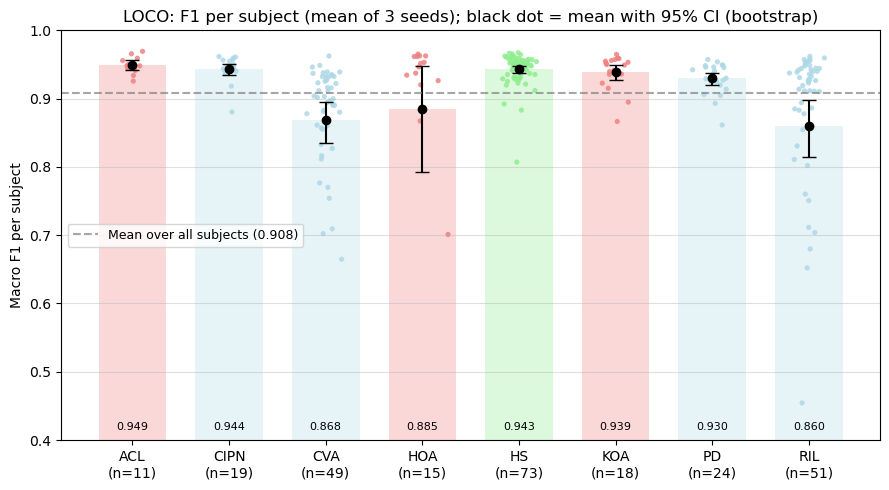

In [13]:
COLOR_MAP = {
        'HS':   ('Healthy',        'lightgreen'),
        'ACL':  ('Orthopaedic',    'lightcoral'),
        'HOA':  ('Orthopaedic',    'lightcoral'),
        'KOA':  ('Orthopaedic',    'lightcoral'),
        'CIPN': ('Neurological',   'lightblue'),
        'CVA':  ('Neurological',   'lightblue'),
        'PD':   ('Neurological',   'lightblue'),
        'RIL':  ('Neurological',   'lightblue'),
    }
pathologies = "ACL CIPN CVA HOA HS KOA PD RIL".split()

plot_loco(per_subj, order=pathologies, colors={c: COLOR_MAP[c][1] for c in pathologies}, ref=per_subj.f1.mean())

En todas las cohortes la mayoría de sujetos supera 0.9, con una minoría de casos de bajo rendimiento

In [18]:
resumen = per_subj.groupby('cohort')['f1'].agg(
    total_sujetos='count',
    menos_085=lambda x: (x < 0.85).sum(),
    proporcion=lambda x: (x < 0.85).mean()
)

display(resumen)

,total_sujetos,menos_085,proporcion
cohort,,,
ACL,11,0,0.000000
CIPN,19,0,0.000000
CVA,49,11,0.224490
HOA,15,2,0.133333
HS,73,1,0.013699
KOA,18,0,0.000000
PD,24,0,0.000000
RIL,51,12,0.235294


In [24]:
worst_subjs = []

for c in ["HOA", "CVA", "RIL"]:
    print(c)
    sub_c = per_subj[per_subj.cohort == c].sort_values("f1")
    display(sub_c.head(10))
    bad_ones = sub_c[sub_c.f1 < 0.5]
    for _, row in bad_ones.iterrows():
        worst_subjs.append((row['cohort'], row['subject']))

HOA


,cohort,subject,f1
80,HOA,HOA_10,0.324535
88,HOA,HOA_4,0.701119
91,HOA,HOA_7,0.867209
84,HOA,HOA_14,0.920277
79,HOA,HOA_1,0.926323
85,HOA,HOA_15,0.934350
87,HOA,HOA_3,0.937272
83,HOA,HOA_13,0.946290
86,HOA,HOA_2,0.951393
89,HOA,HOA_5,0.953119


CVA


,cohort,subject,f1
78,CVA,CVA_9,0.289088
56,CVA,CVA_33,0.664836
42,CVA,CVA_20,0.702288
60,CVA,CVA_37,0.709323
44,CVA,CVA_22,0.754050
38,CVA,CVA_17,0.770091
43,CVA,CVA_21,0.776433
74,CVA,CVA_5,0.811488
31,CVA,CVA_10,0.816420
50,CVA,CVA_28,0.827177


RIL


,cohort,subject,f1
222,RIL,RIL_21,0.221525
217,RIL,RIL_17,0.292707
212,RIL,RIL_12,0.454421
230,RIL,RIL_29,0.652176
233,RIL,RIL_31,0.679885
259,RIL,RIL_9,0.704052
223,RIL,RIL_22,0.711438
245,RIL,RIL_42,0.750803
240,RIL,RIL_38,0.760116
234,RIL,RIL_32,0.802077


Worst subjects (F1 < 0.5):
Subject: HOA_10, Trial: HOA_10_1
F1: 0.3180


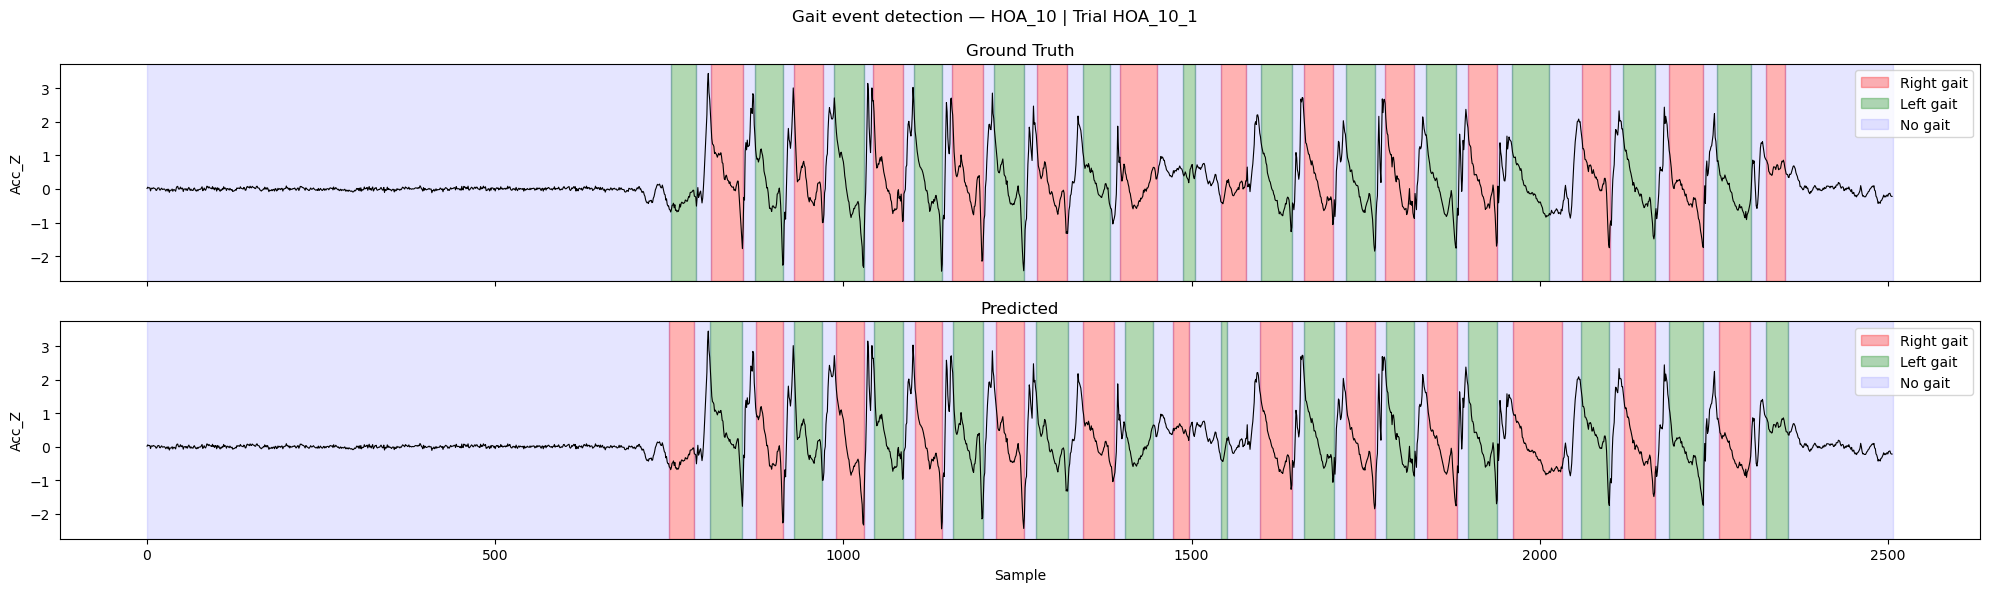

Subject: HOA_10, Trial: HOA_10_2
F1: 0.3199


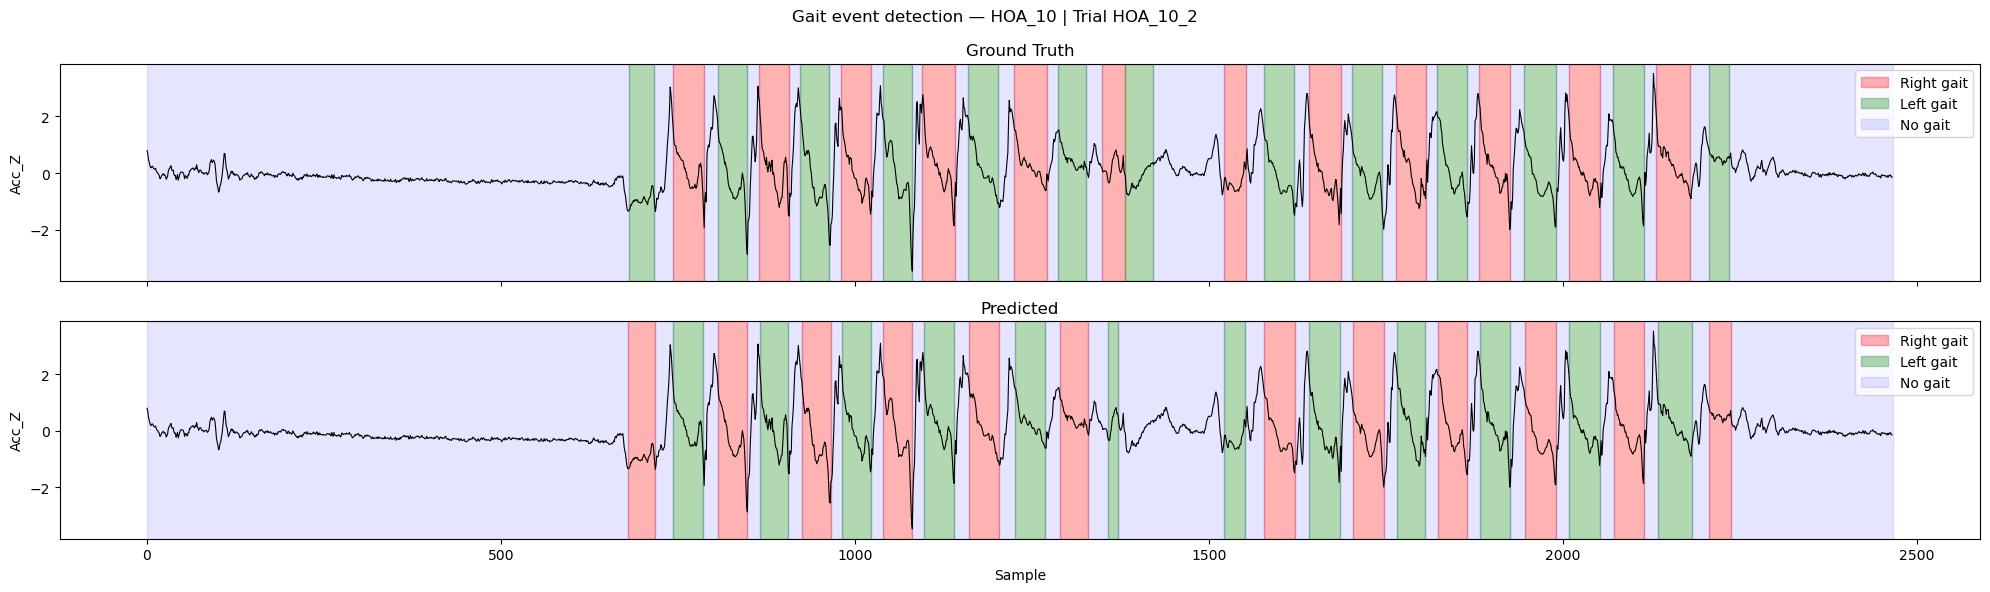

Subject: CVA_9, Trial: CVA_9_1
F1: 0.2993


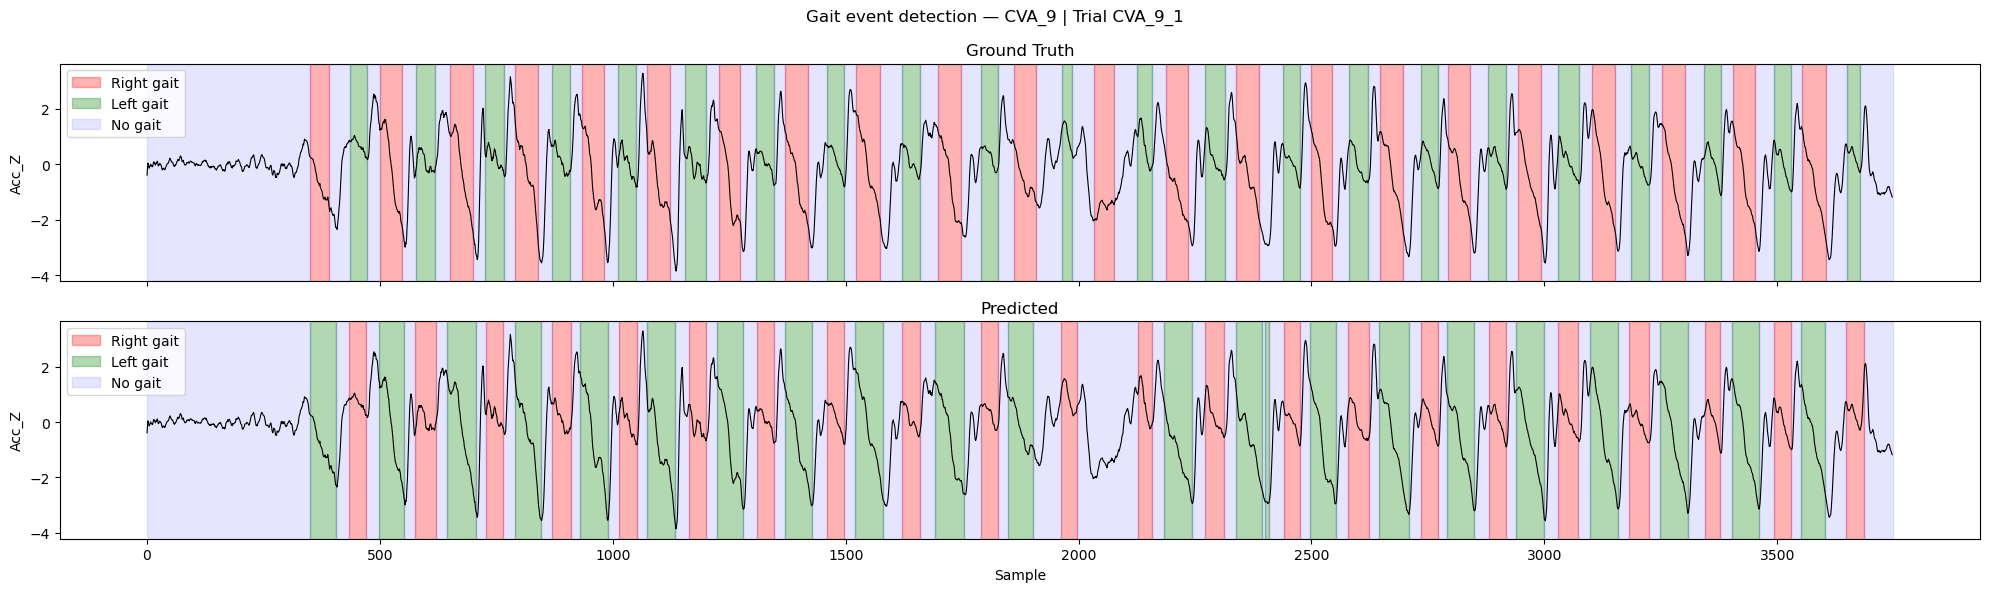

Subject: CVA_9, Trial: CVA_9_2
F1: 0.2991


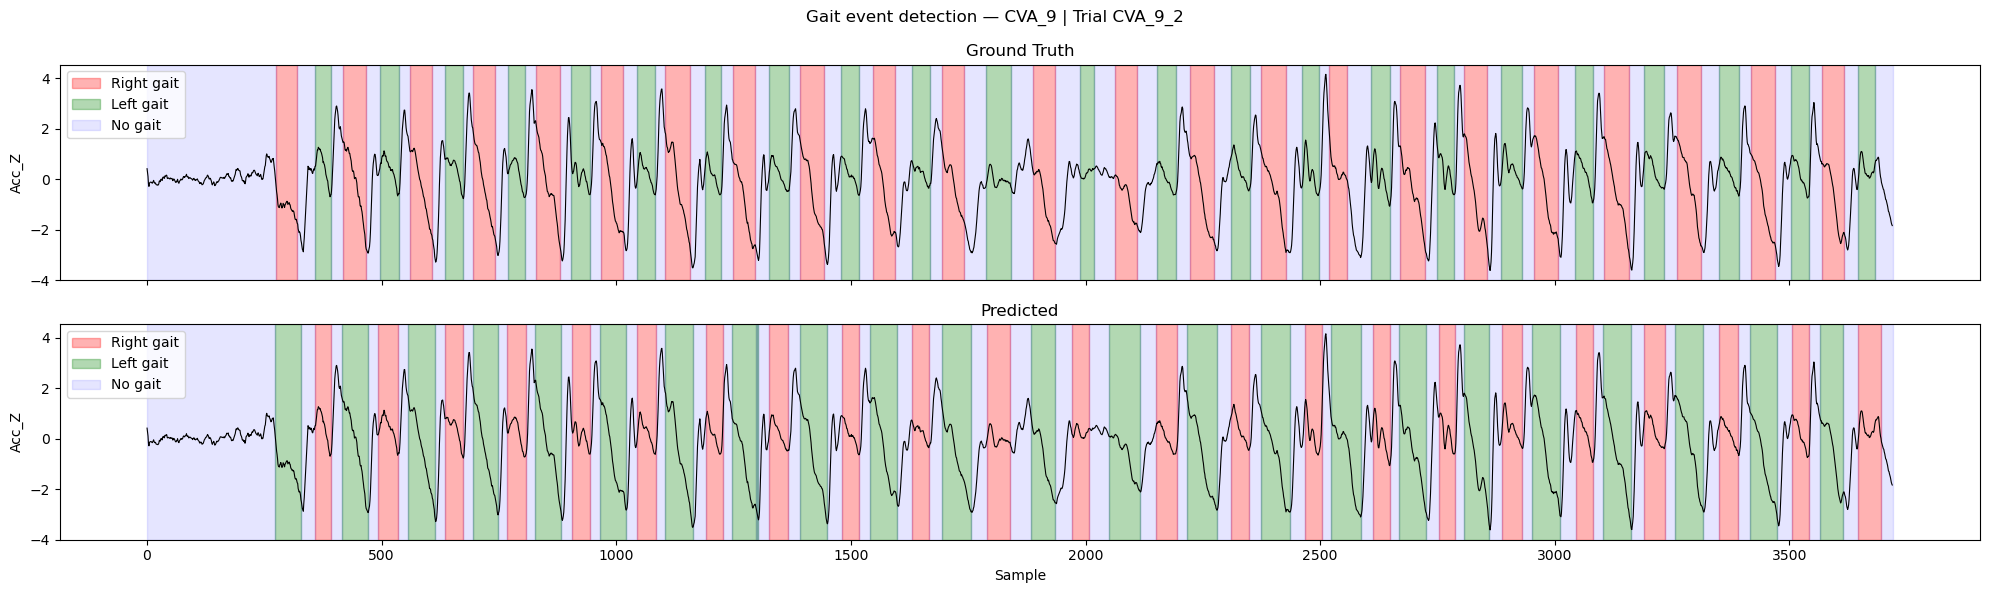

Subject: RIL_21, Trial: RIL_21_1
F1: 0.2315


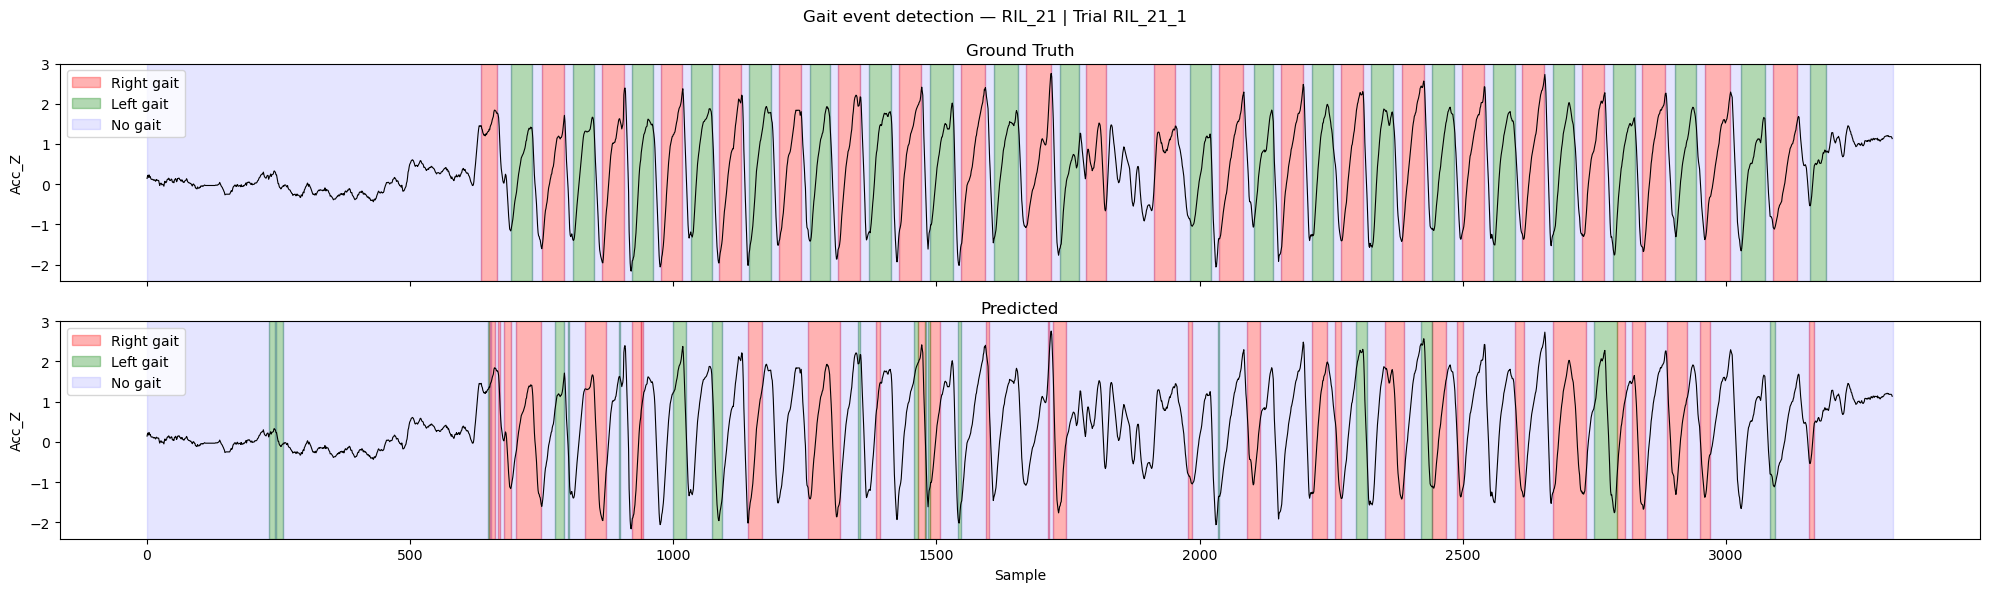

Subject: RIL_21, Trial: RIL_21_2
F1: 0.2274


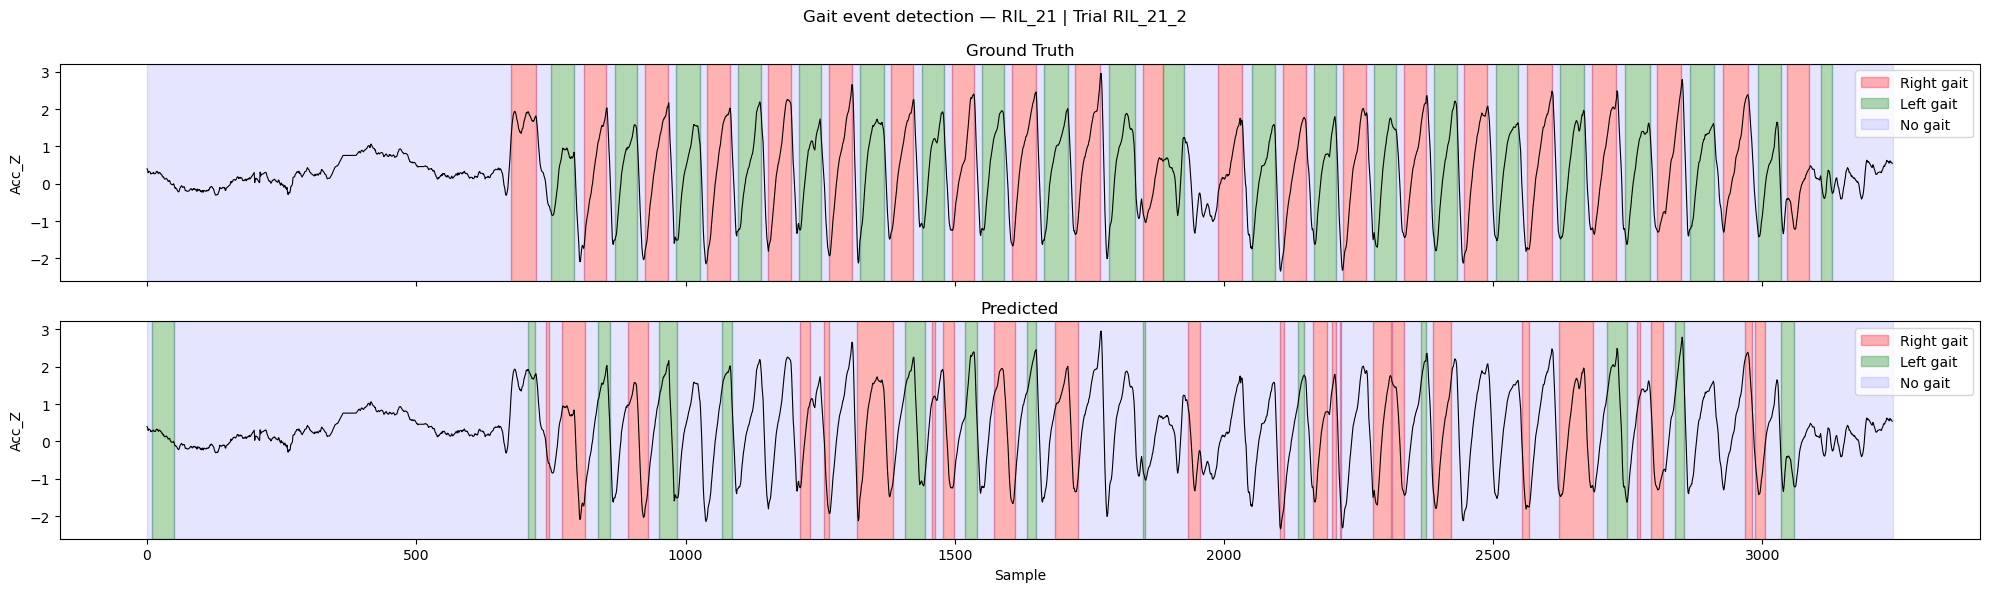

Subject: RIL_21, Trial: RIL_21_3
F1: 0.2207


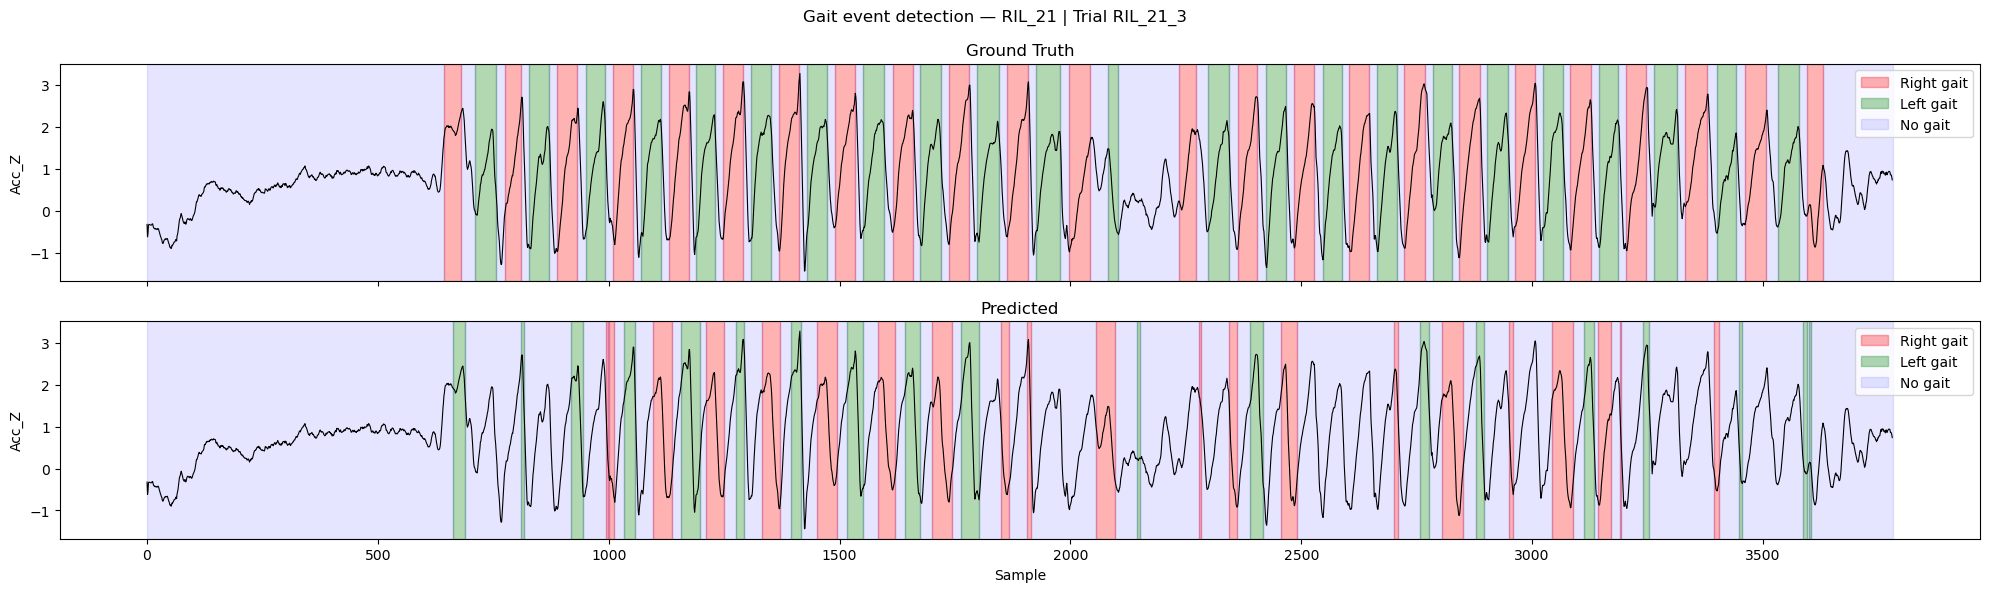

Subject: RIL_21, Trial: RIL_21_4
F1: 0.2060


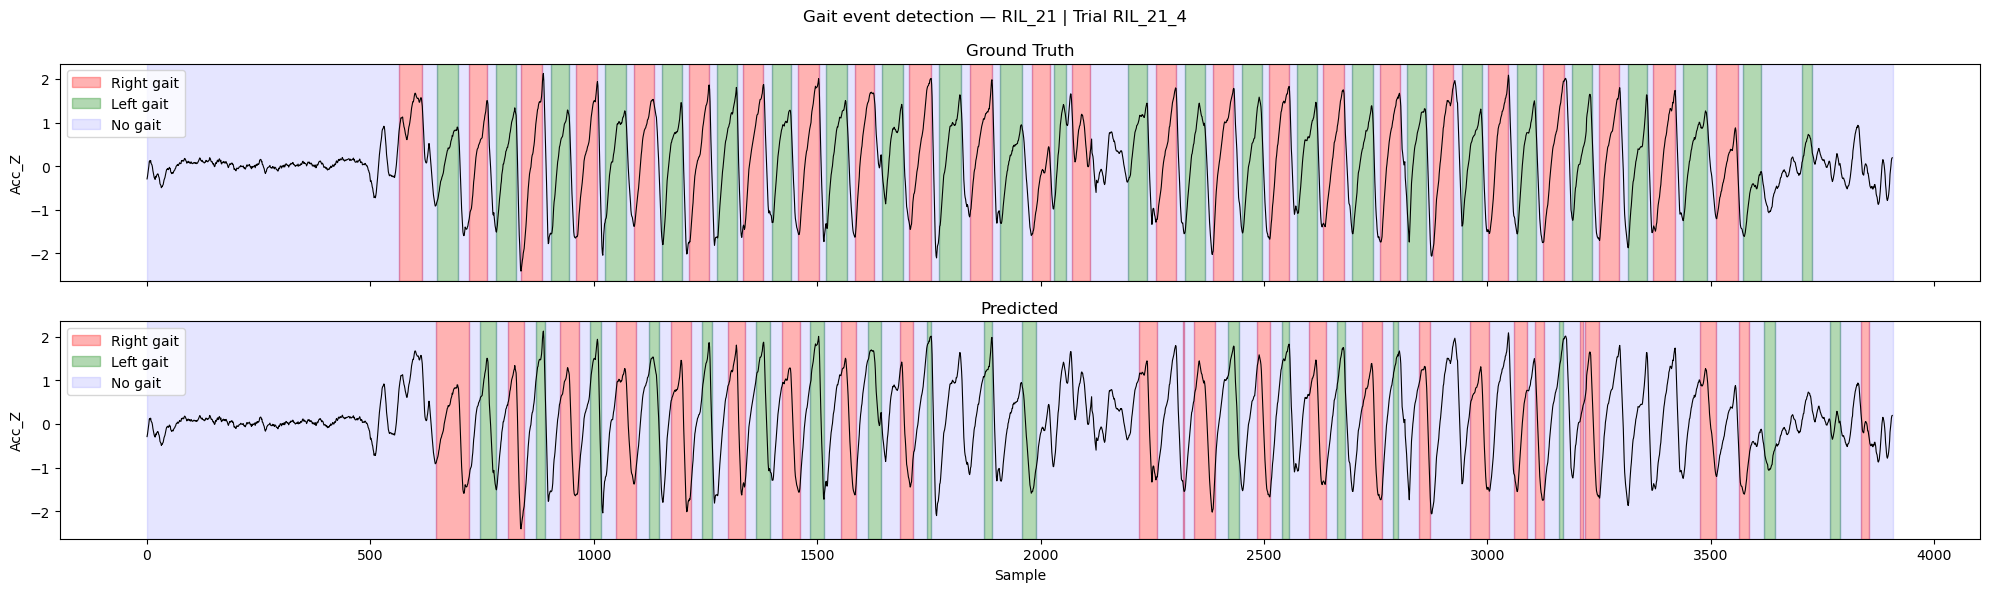

Subject: RIL_21, Trial: RIL_21_5
F1: 0.2205


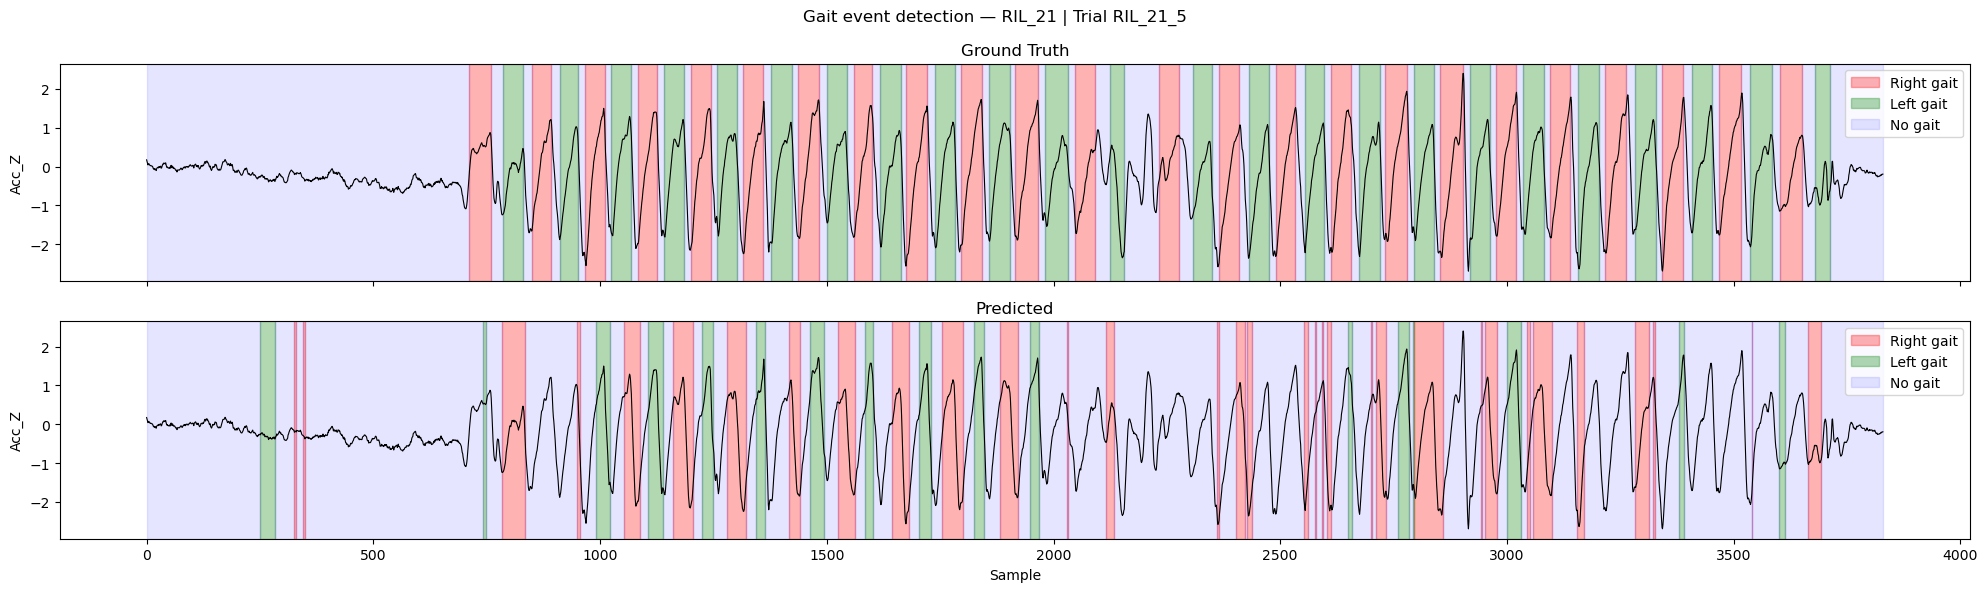

Subject: RIL_17, Trial: RIL_17_1
F1: 0.2906


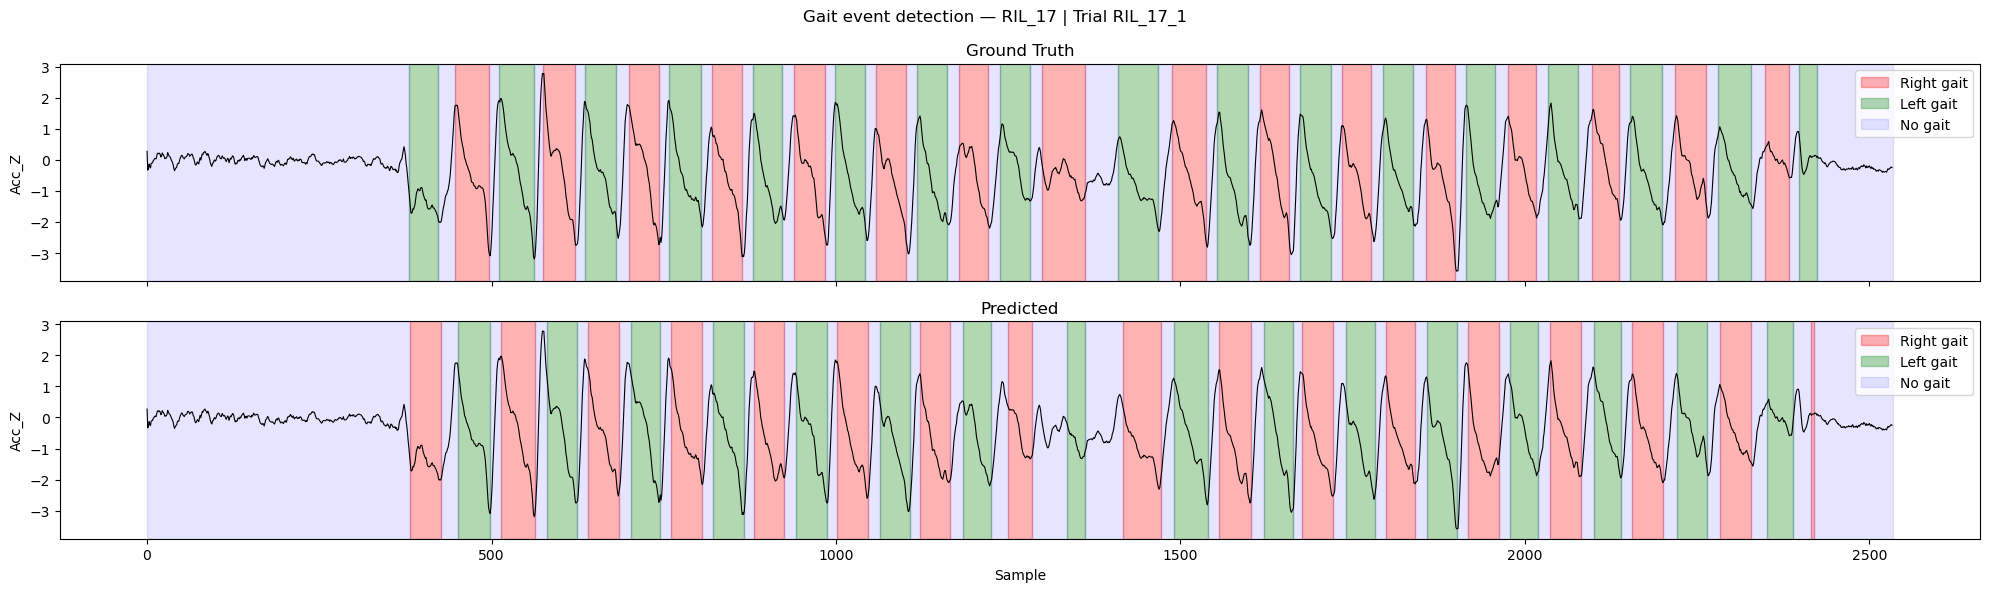

Subject: RIL_17, Trial: RIL_17_2
F1: 0.2915


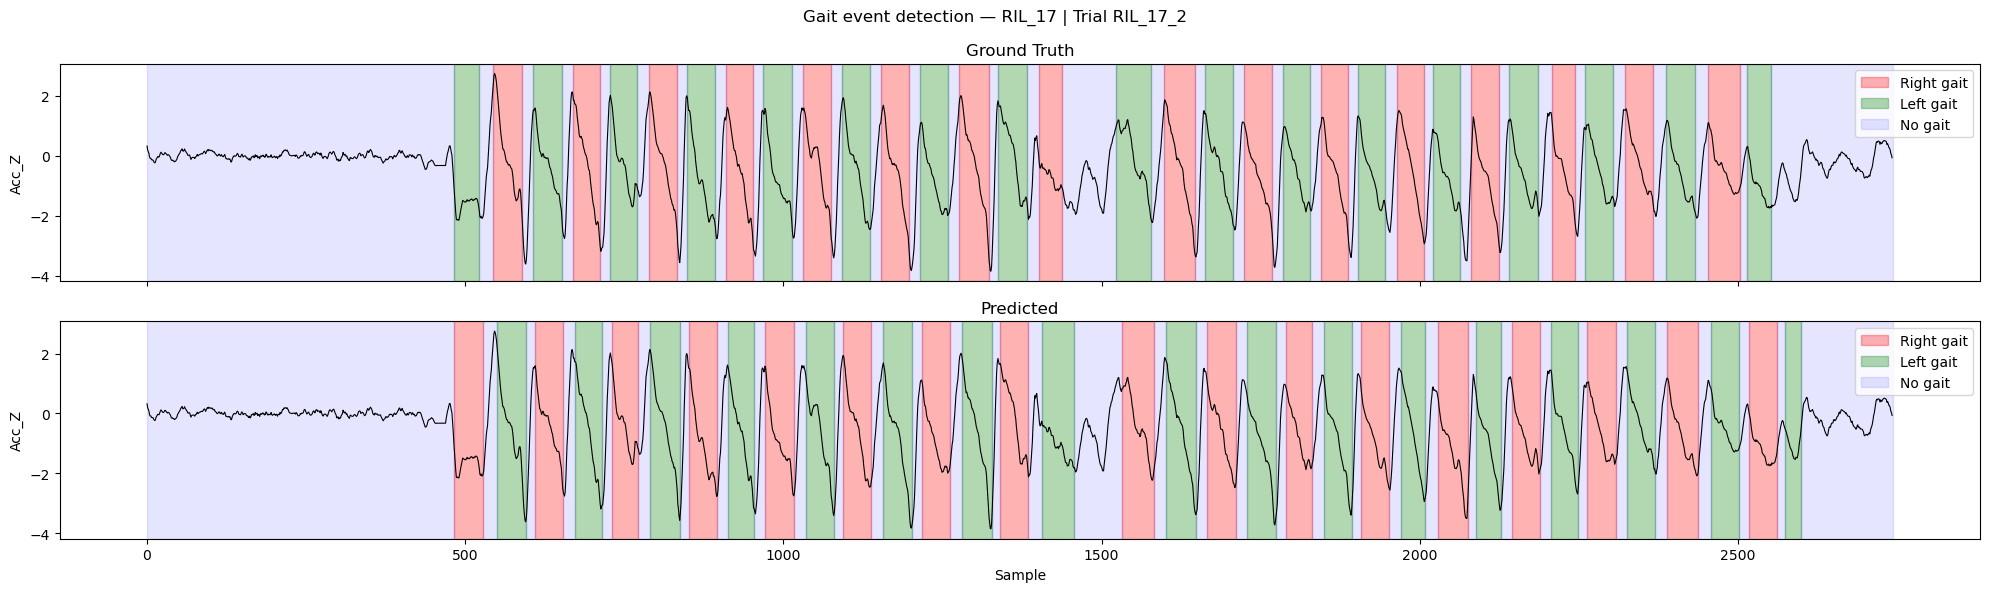

Subject: RIL_17, Trial: RIL_17_3
F1: 0.2934


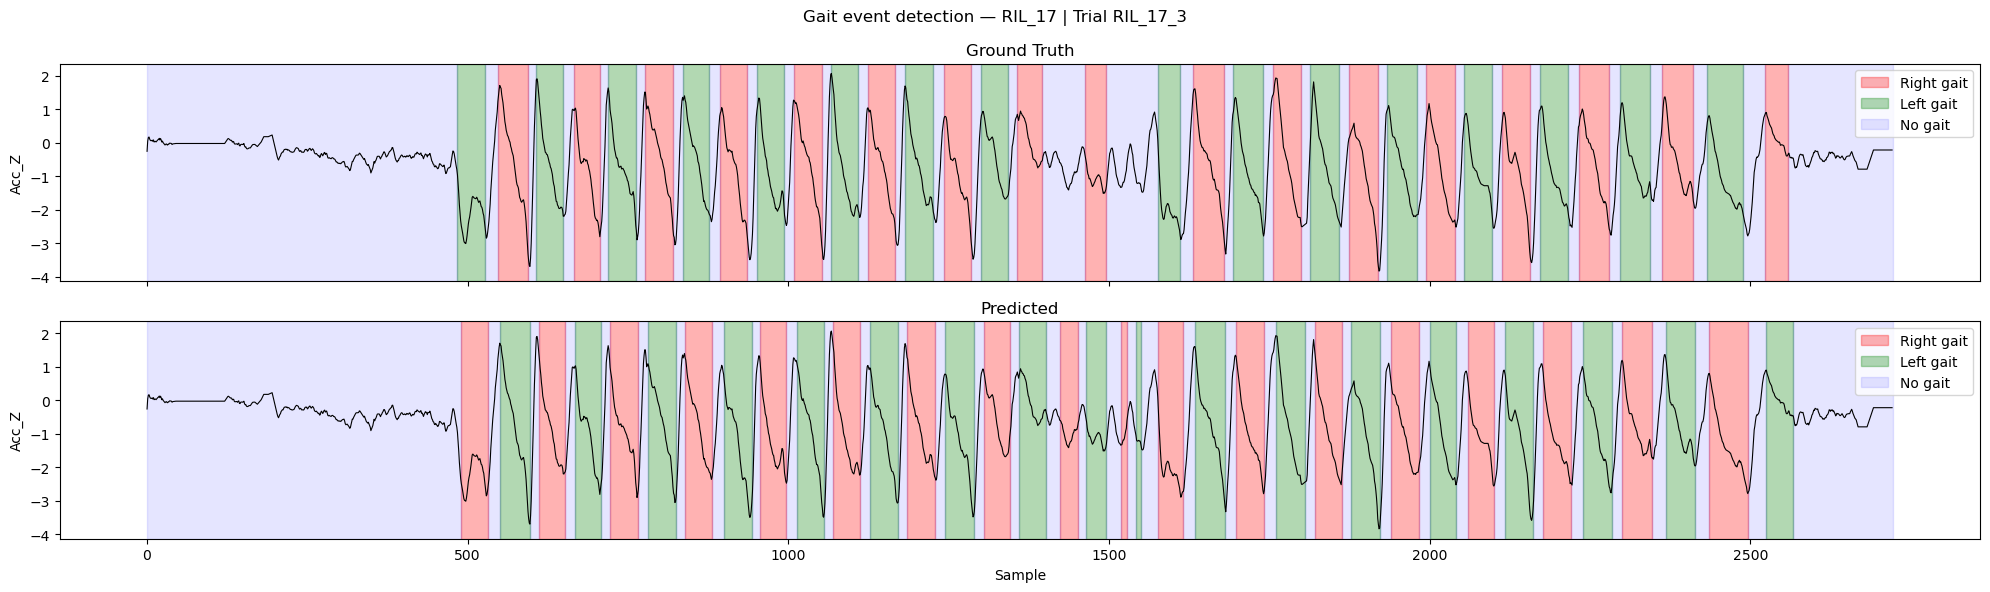

Subject: RIL_17, Trial: RIL_17_4
F1: 0.2964


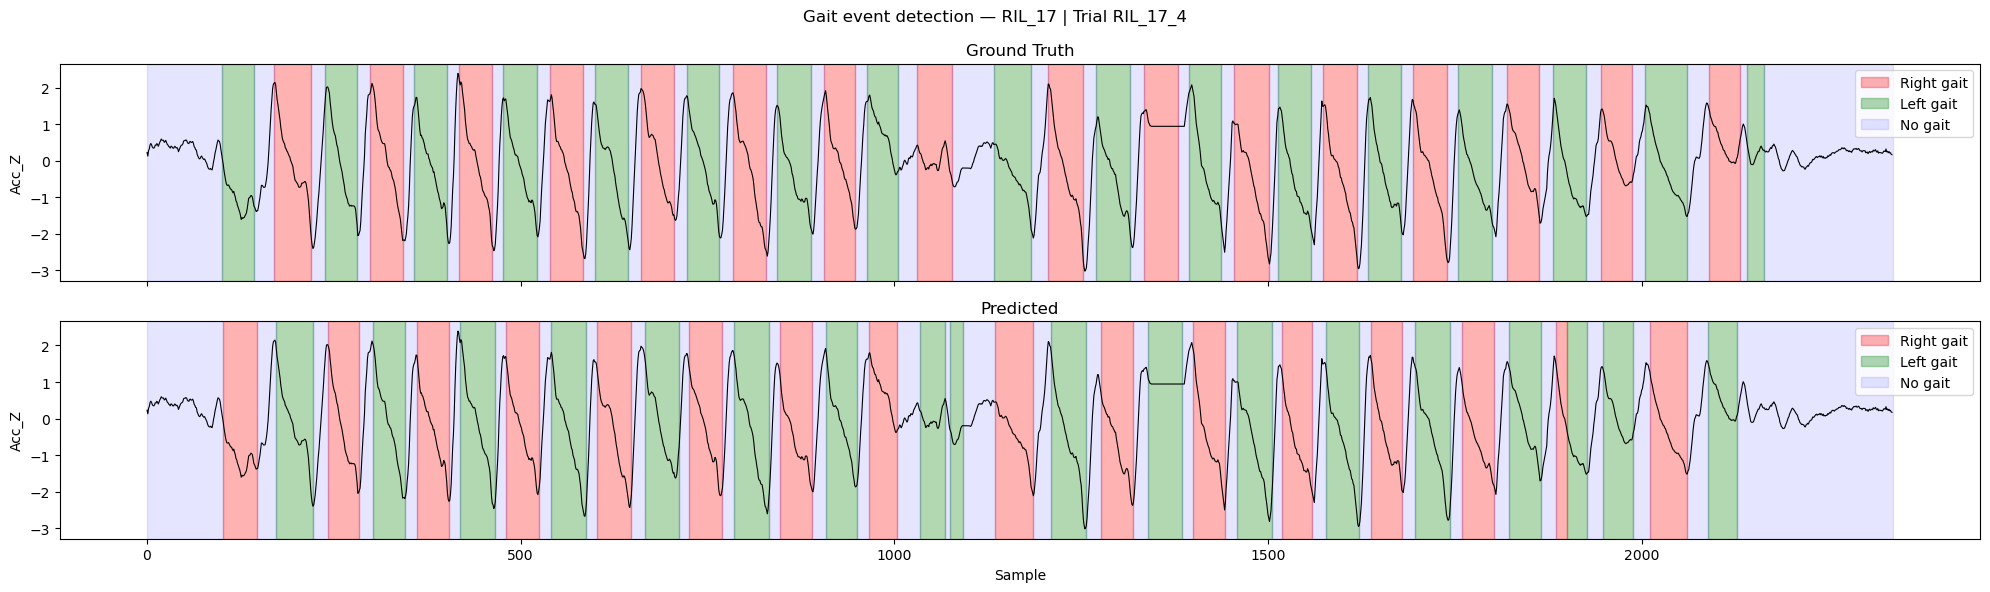

Subject: RIL_17, Trial: RIL_17_5
F1: 0.2949


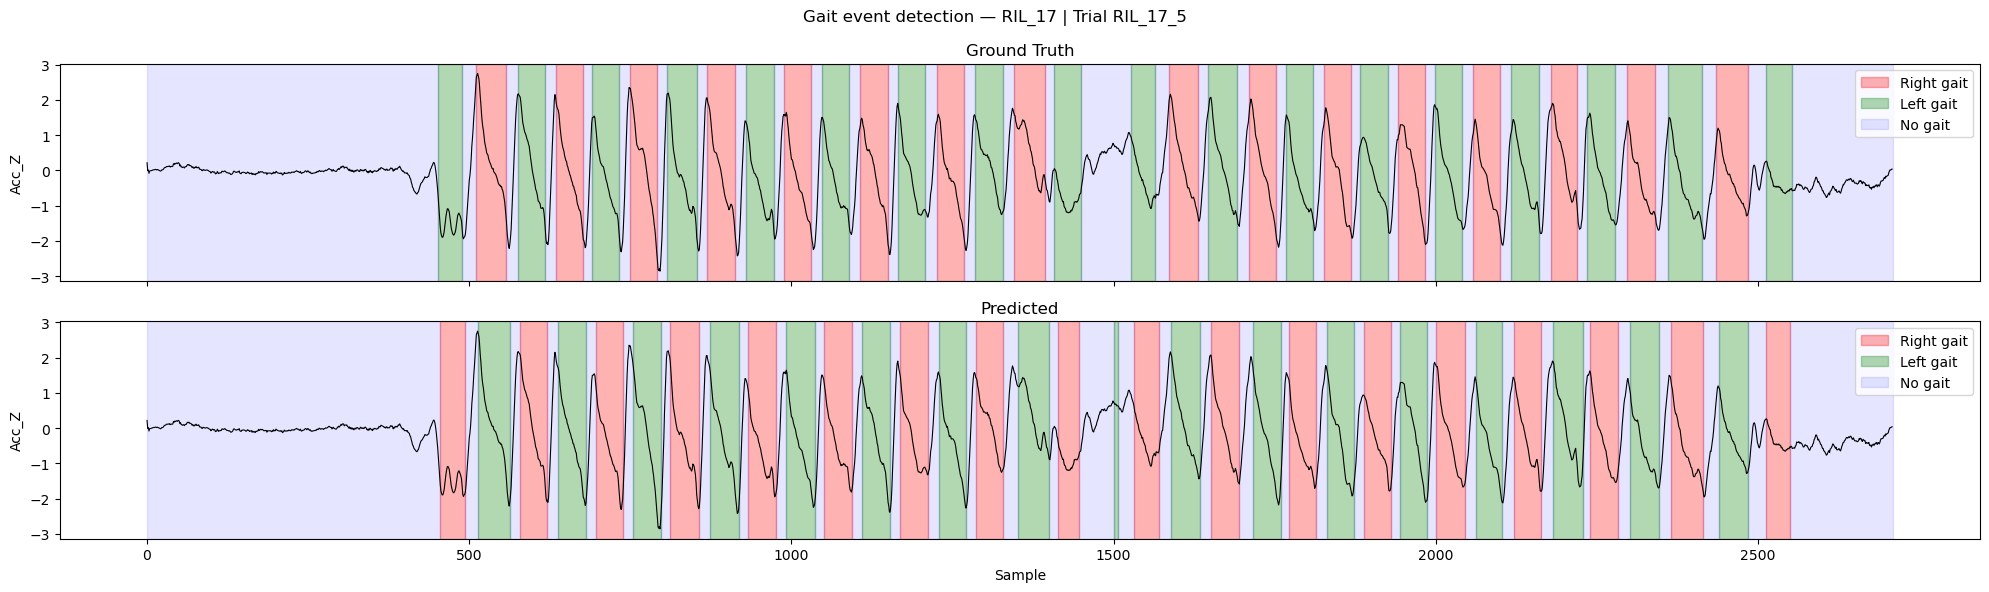

Subject: RIL_12, Trial: RIL_12_1
F1: 0.2128


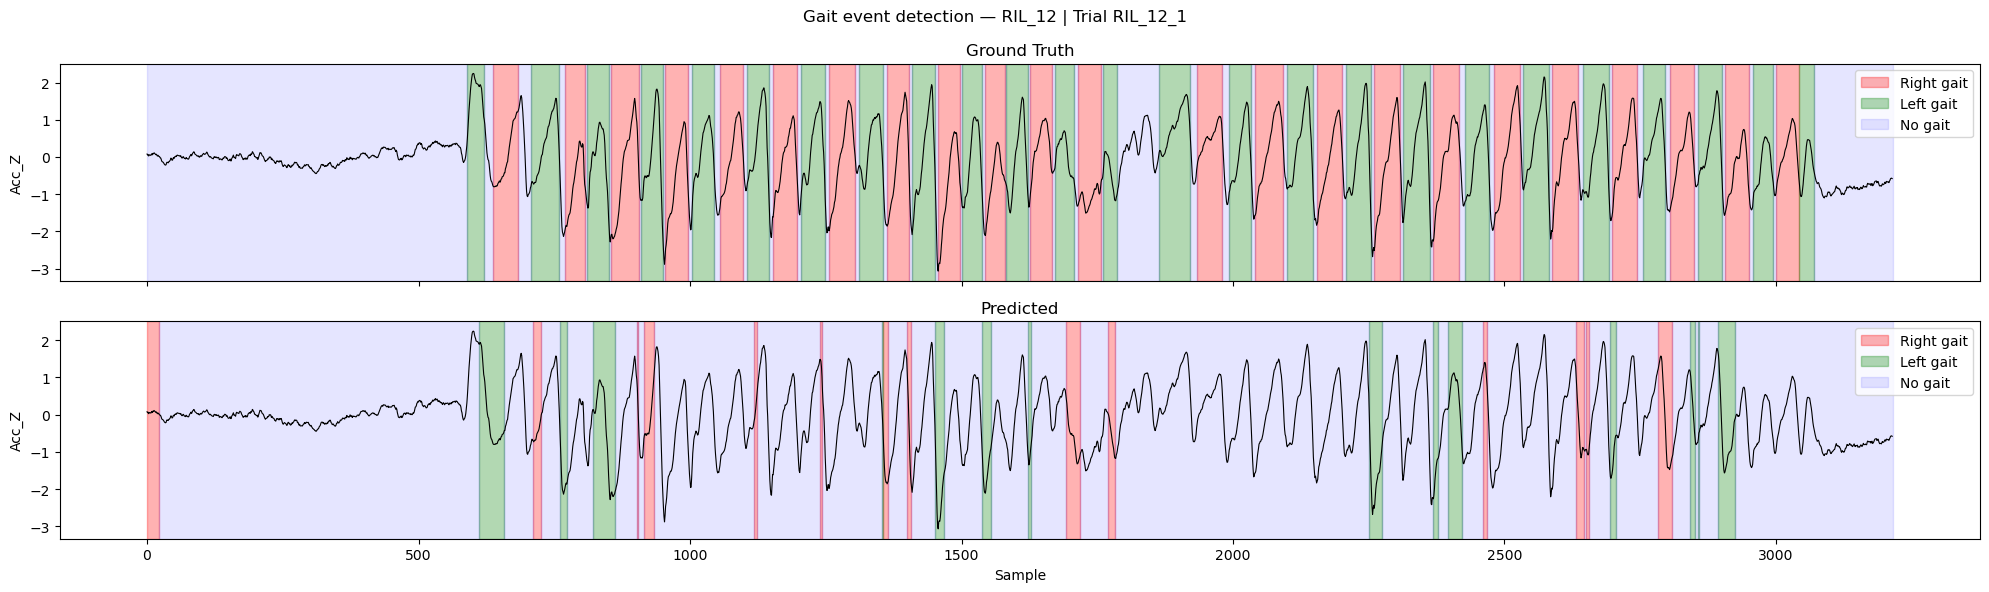

Subject: RIL_12, Trial: RIL_12_10
F1: 0.3612


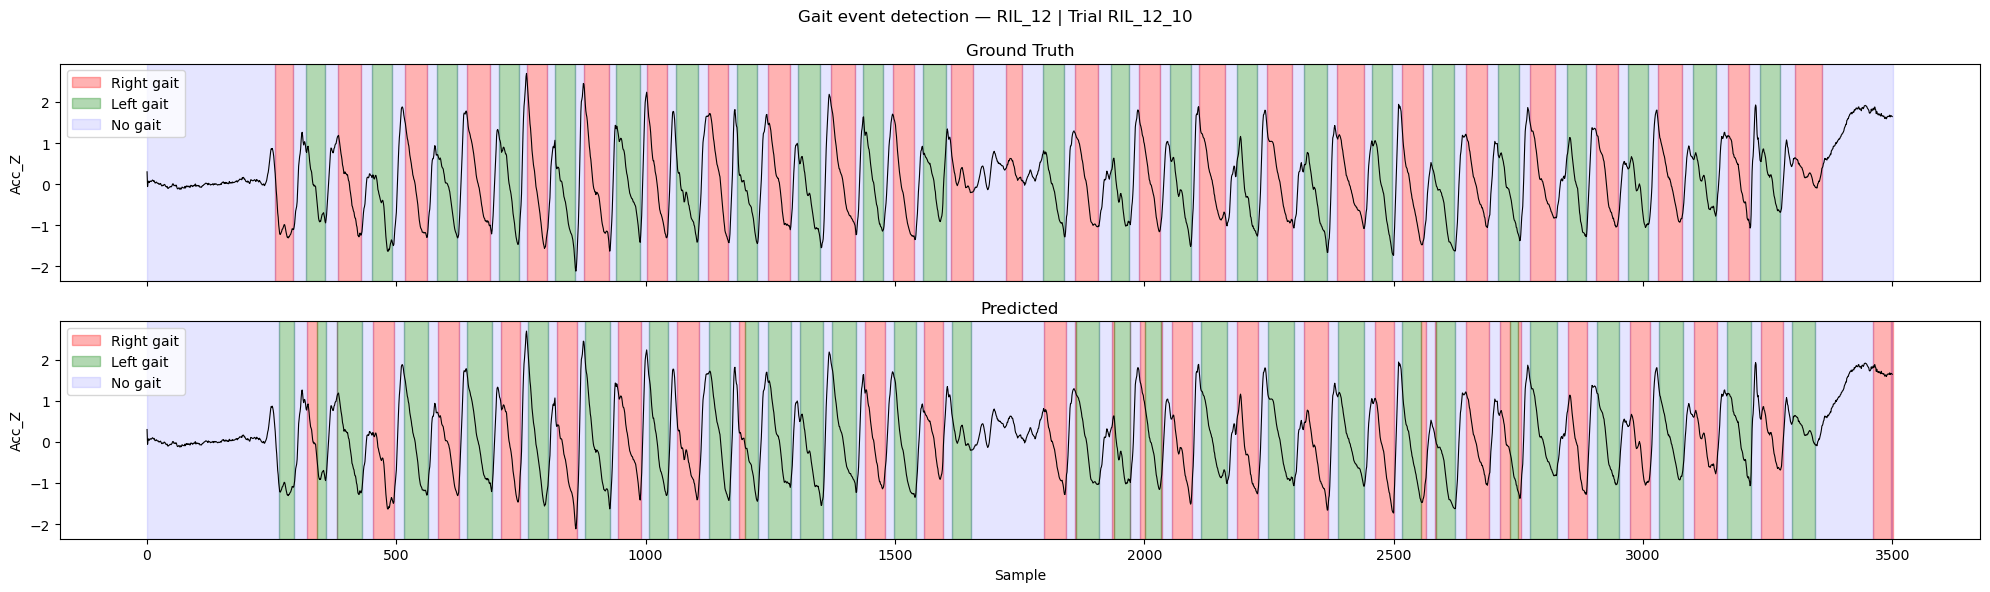

Subject: RIL_12, Trial: RIL_12_11
F1: 0.9393


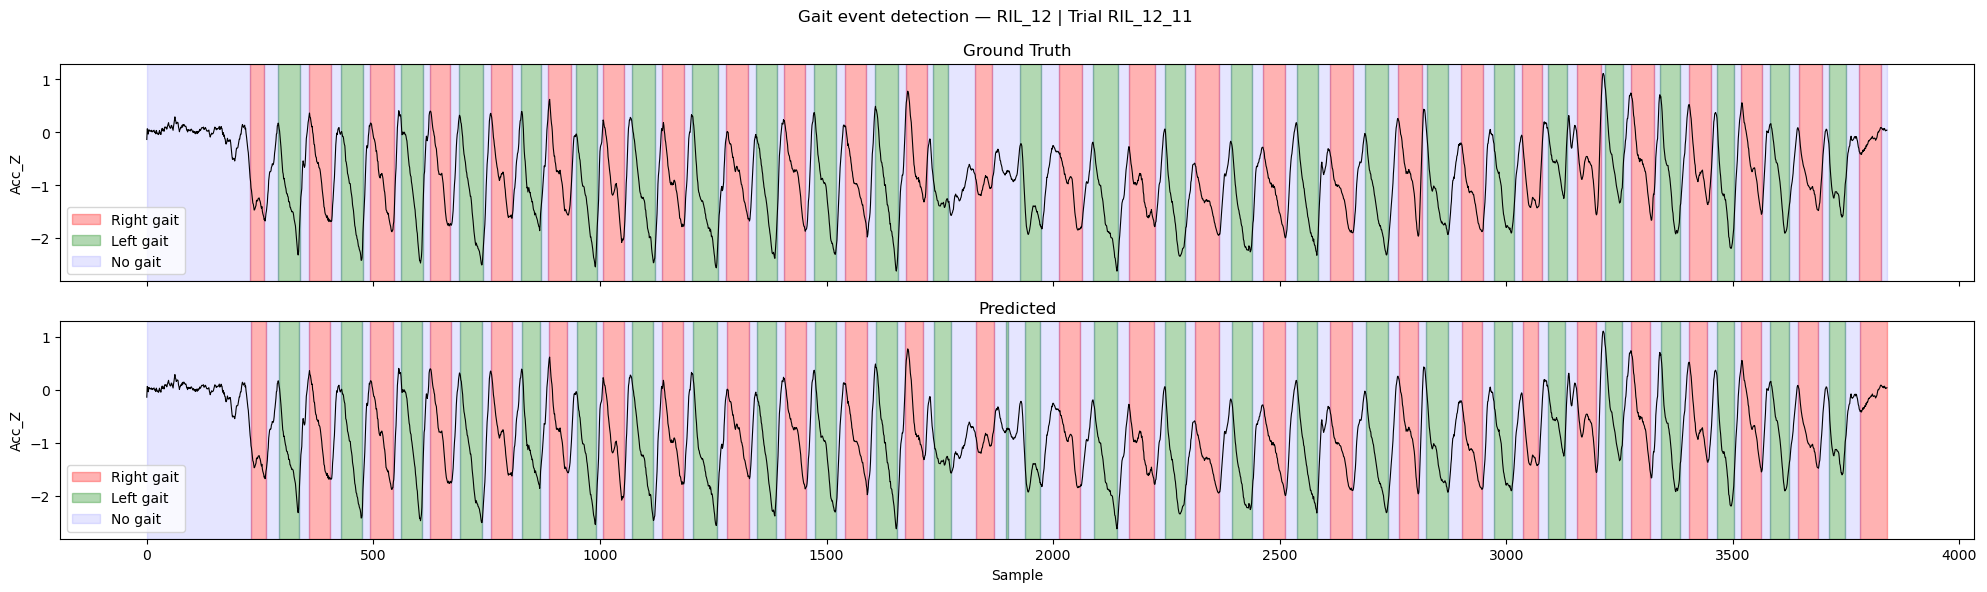

Subject: RIL_12, Trial: RIL_12_12
F1: 0.9078


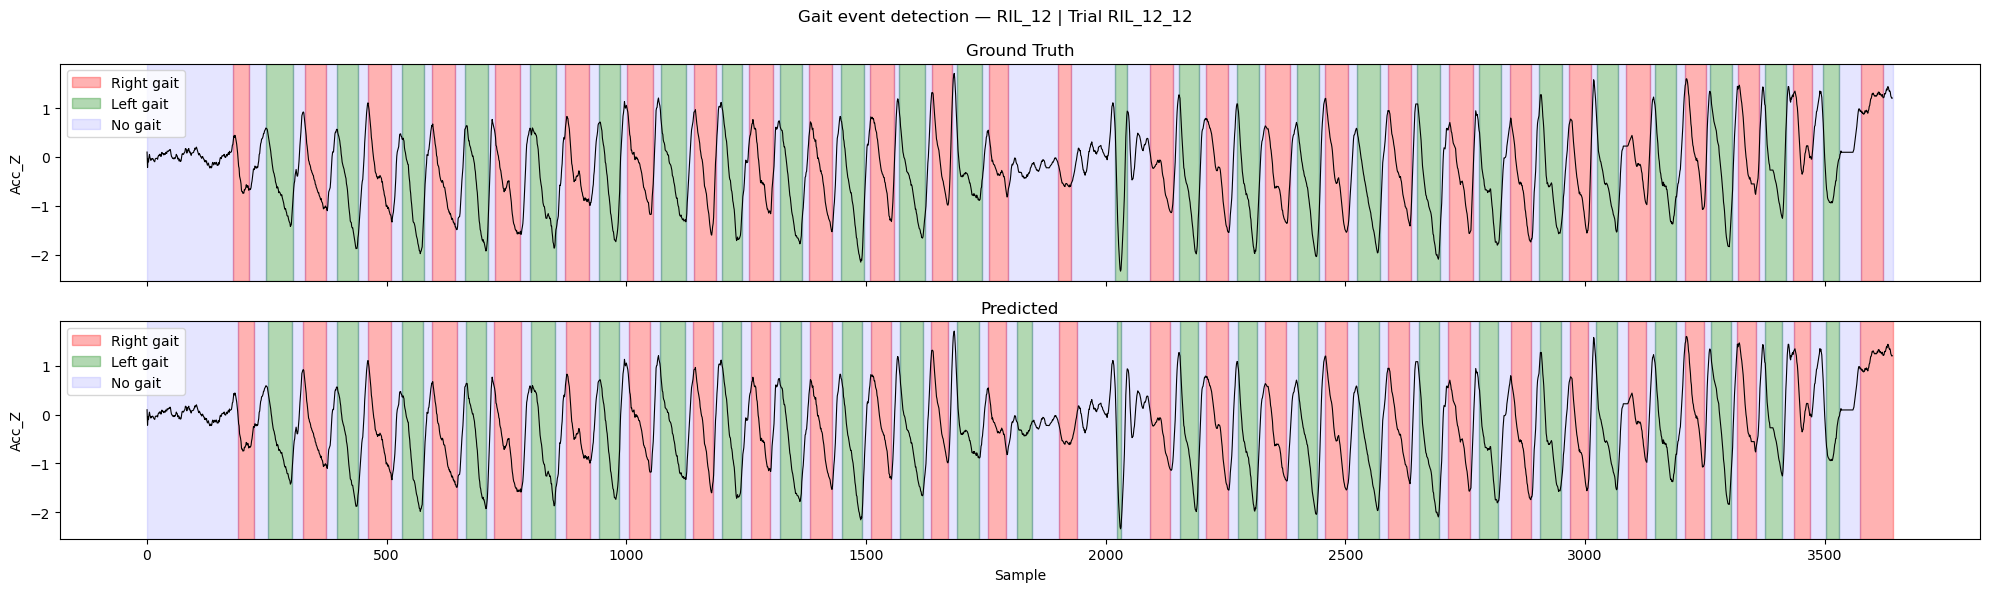

Subject: RIL_12, Trial: RIL_12_13
F1: 0.8814


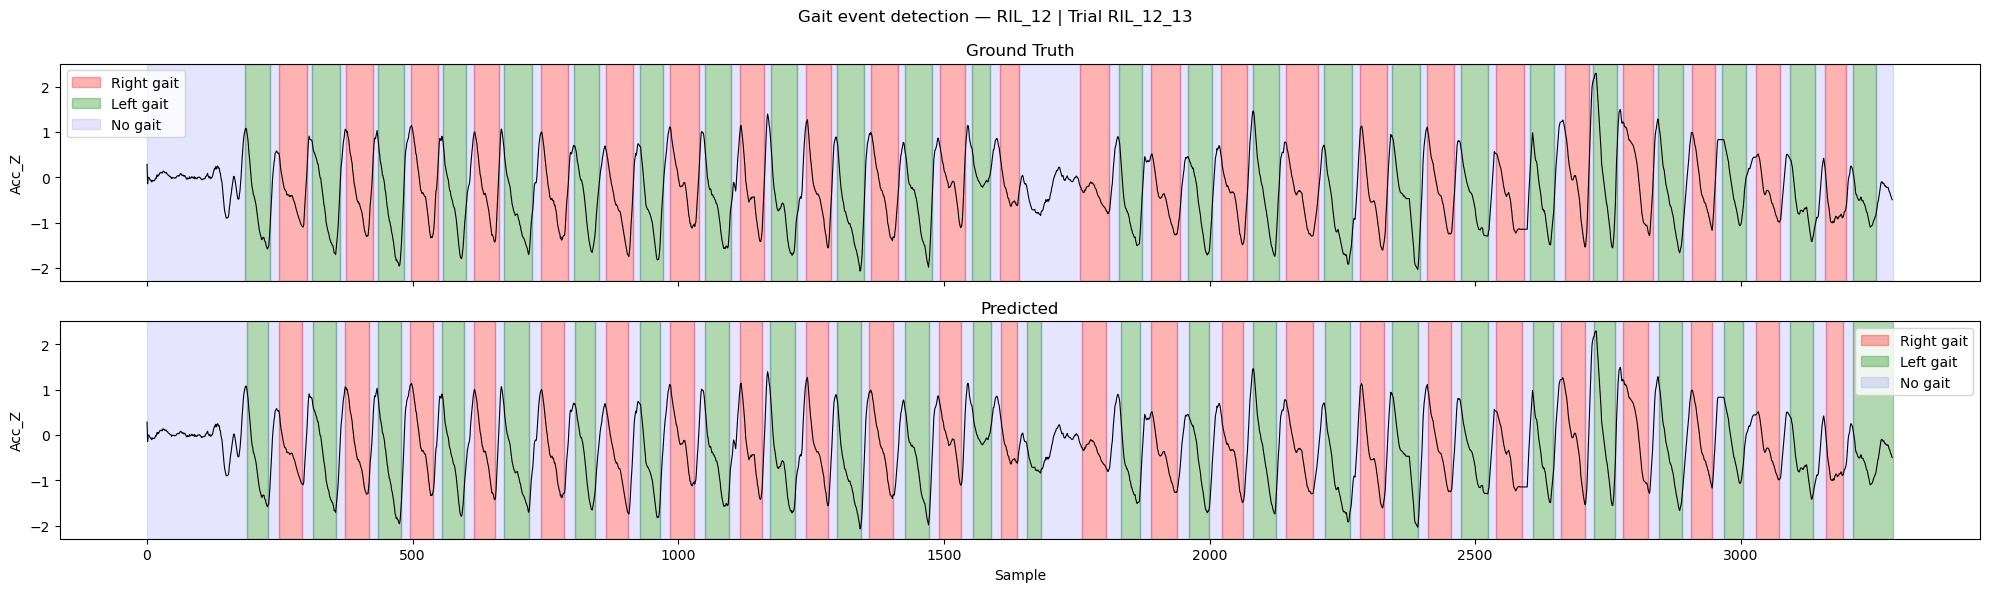

Subject: RIL_12, Trial: RIL_12_14
F1: 0.8991


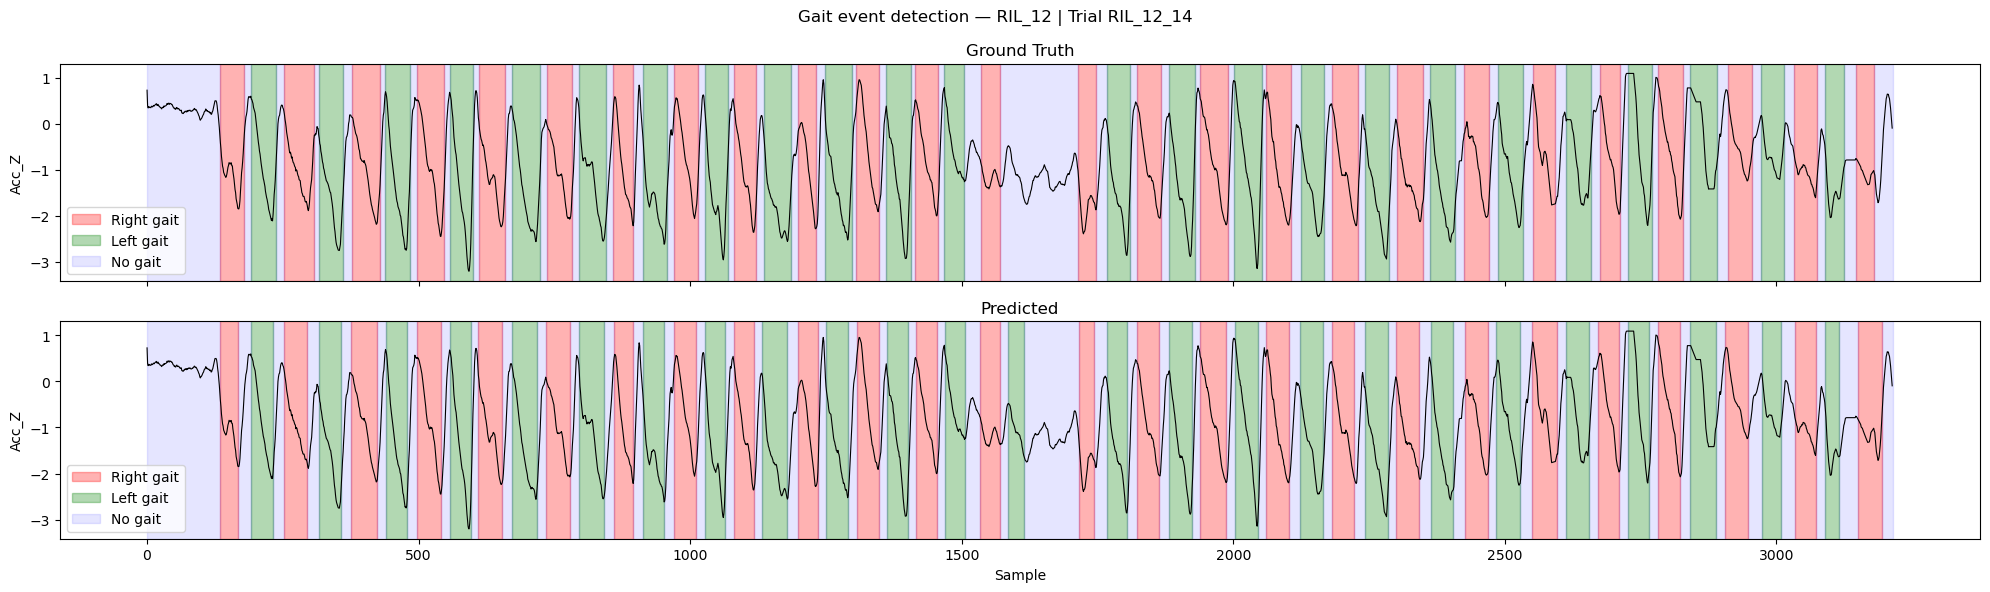

Subject: RIL_12, Trial: RIL_12_2
F1: 0.1946


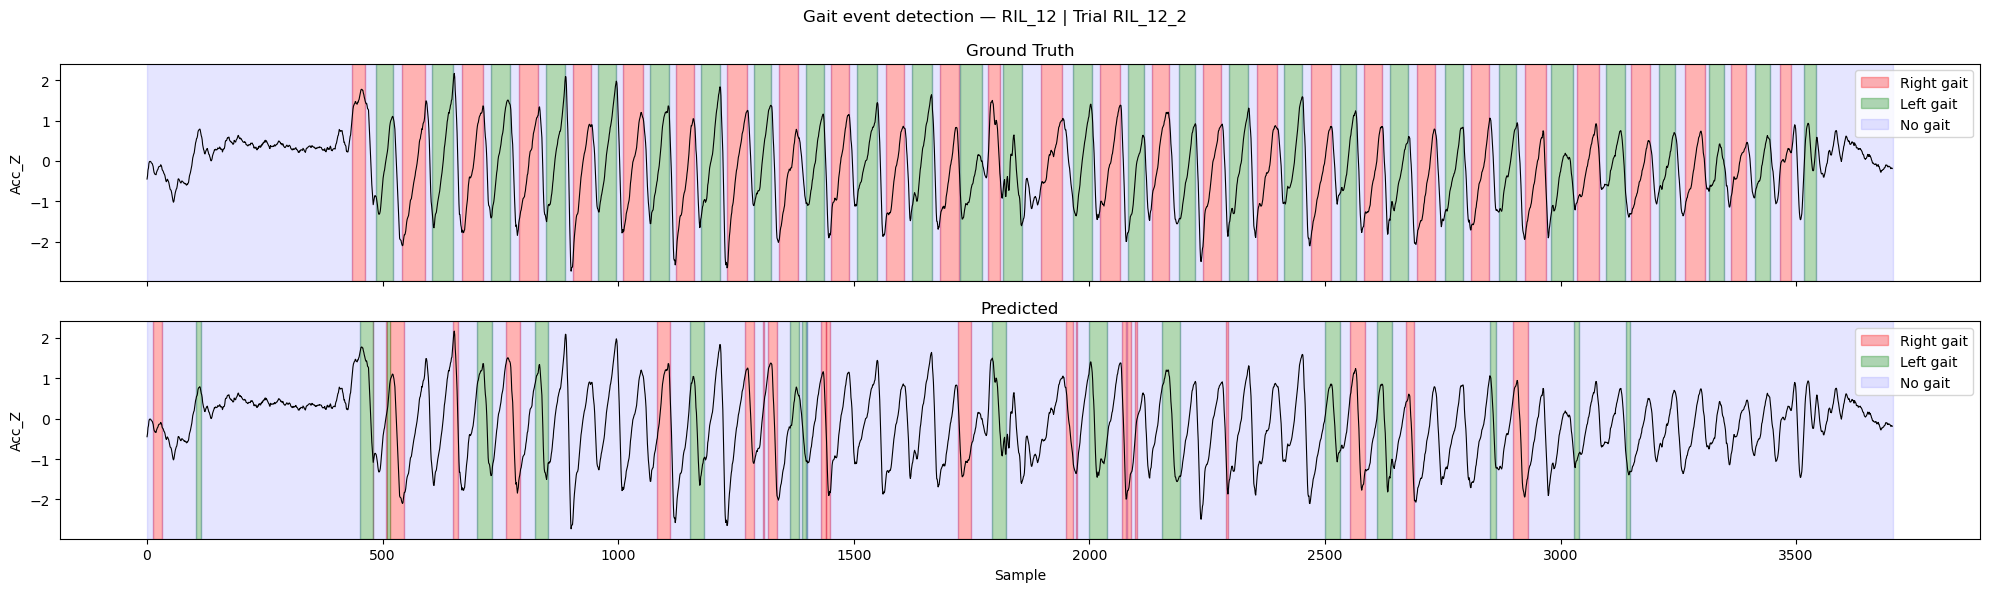

Subject: RIL_12, Trial: RIL_12_3
F1: 0.1947


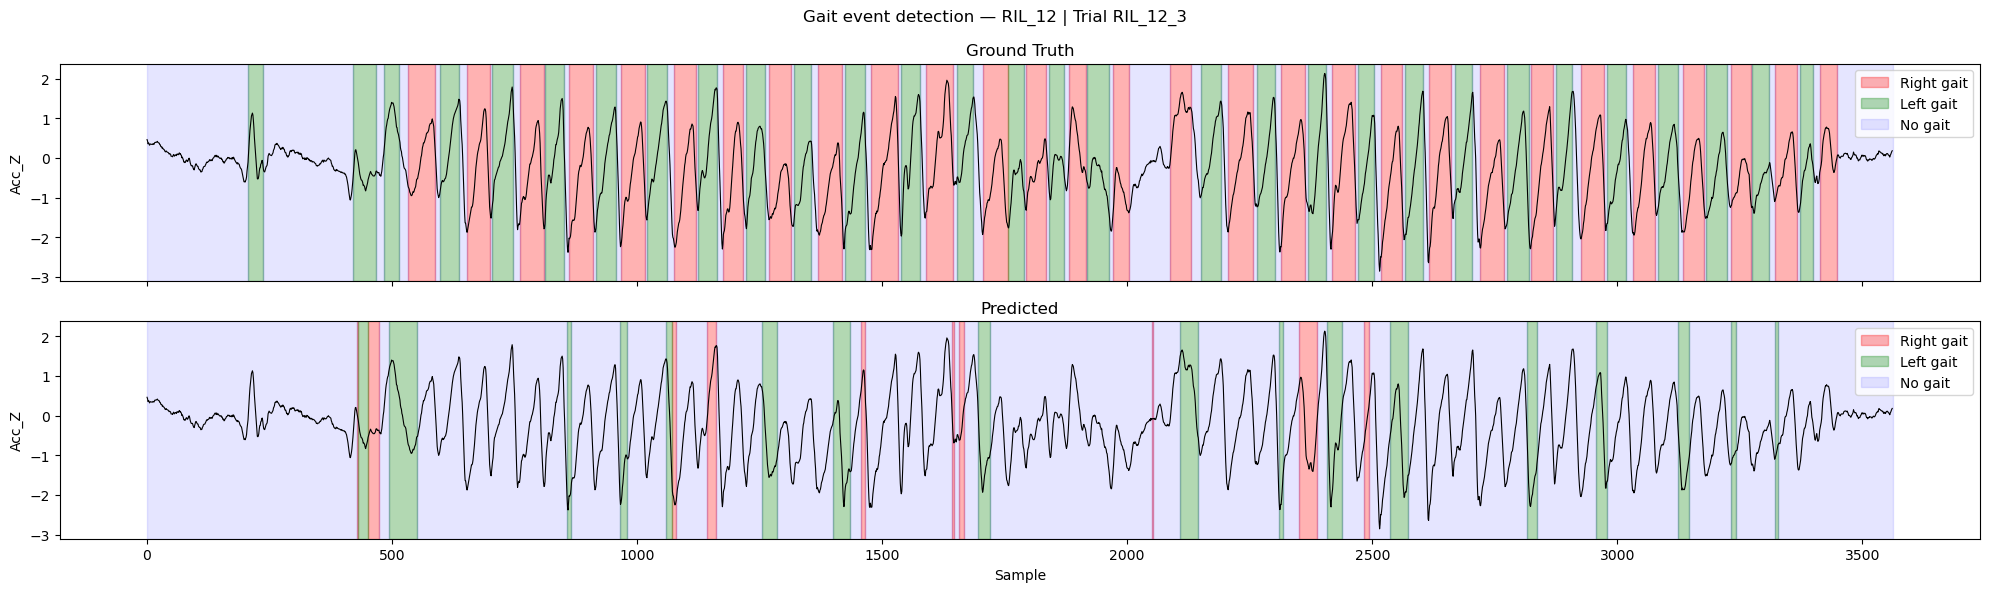

Subject: RIL_12, Trial: RIL_12_4
F1: 0.1711


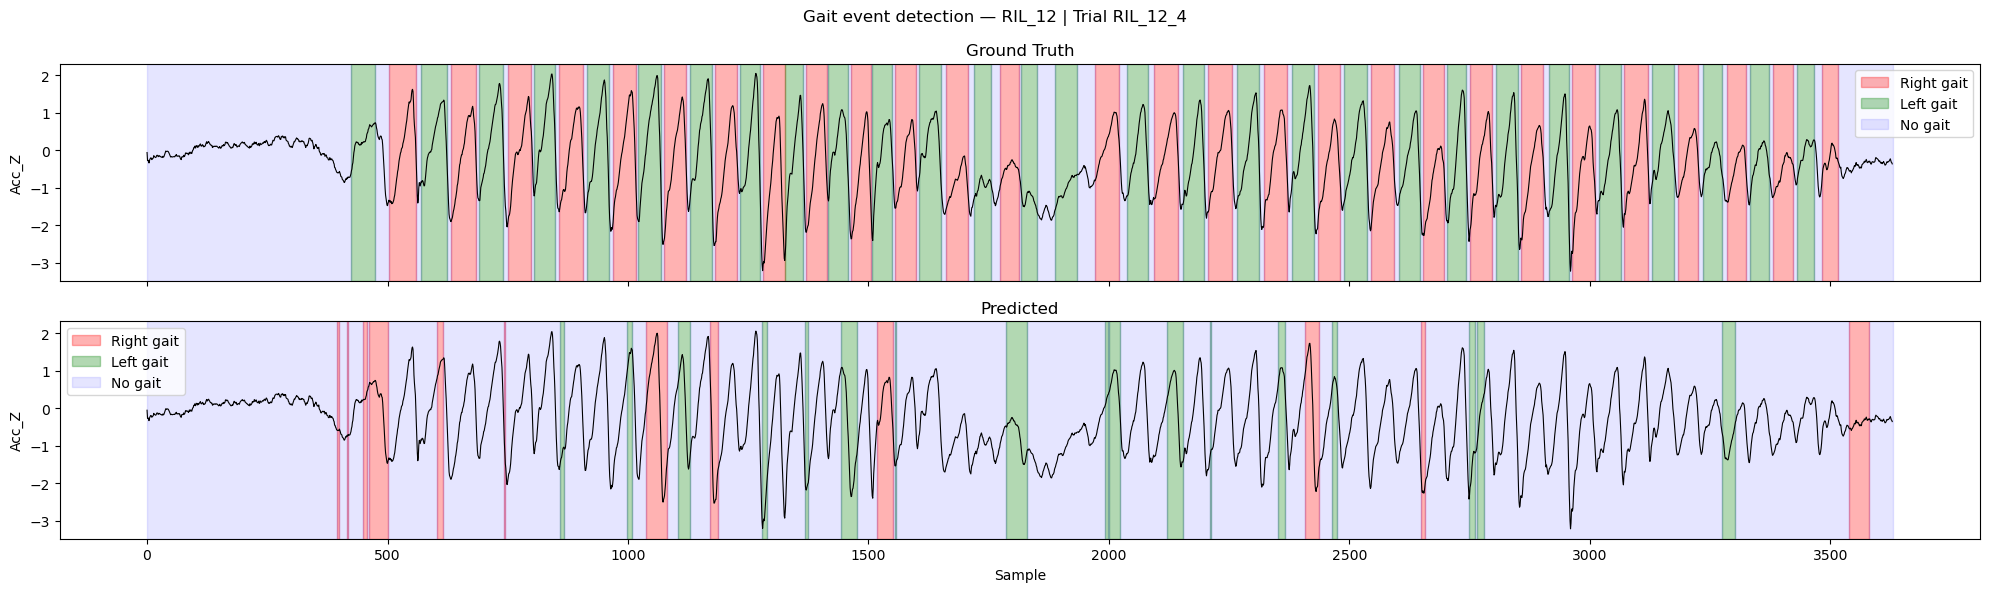

Subject: RIL_12, Trial: RIL_12_5
F1: 0.1834


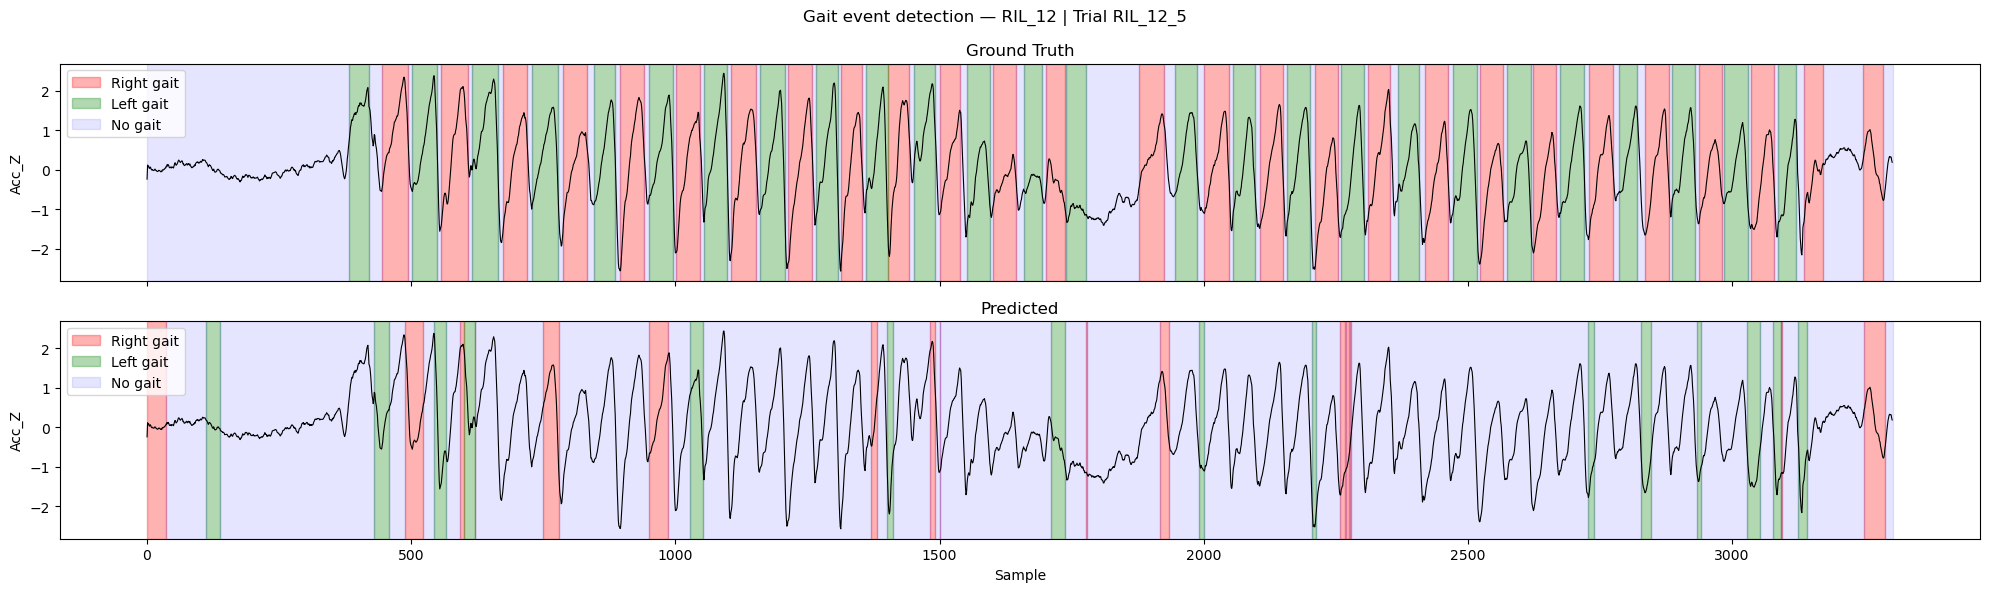

Subject: RIL_12, Trial: RIL_12_6
F1: 0.3400


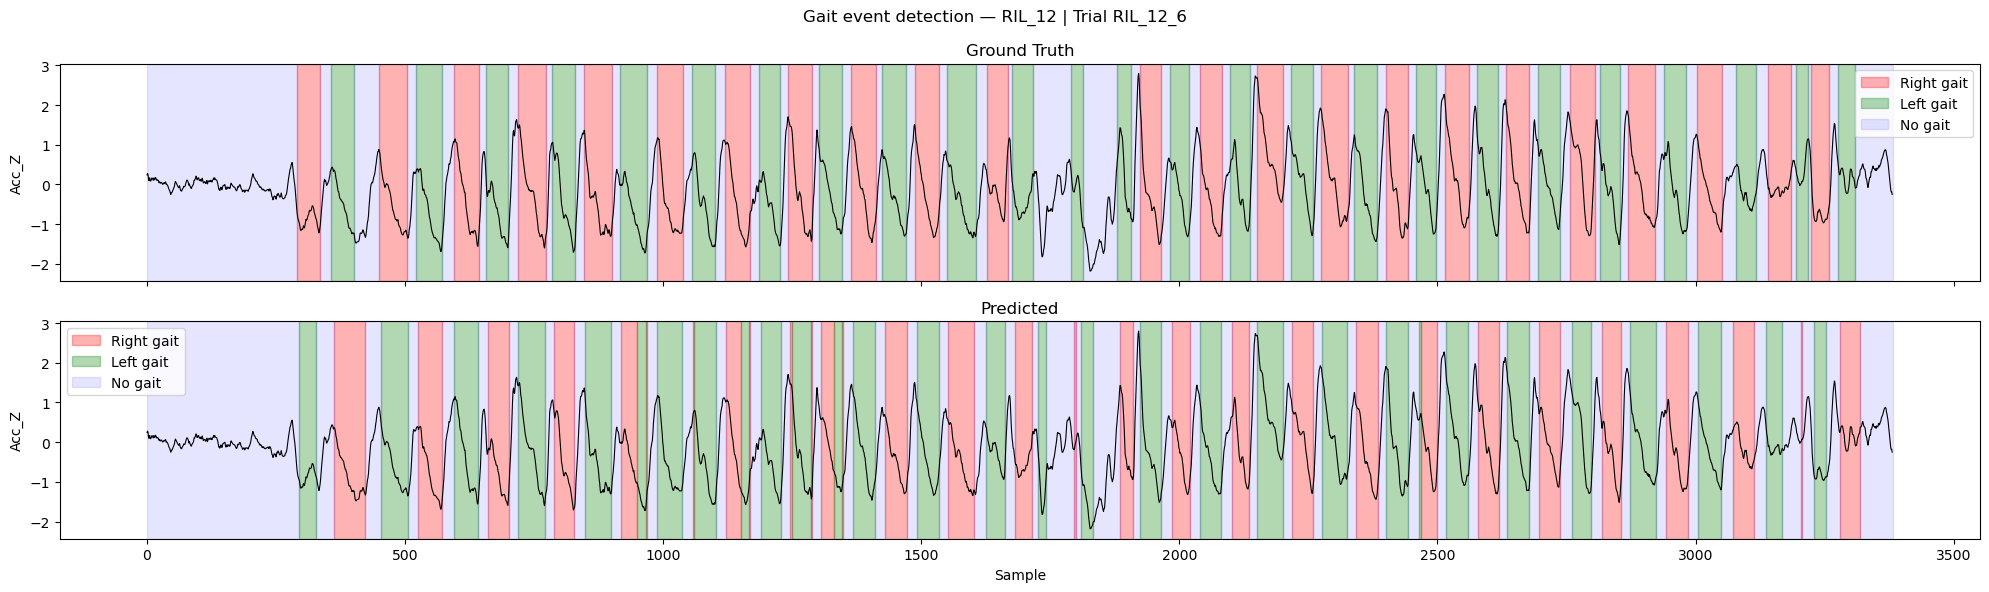

Subject: RIL_12, Trial: RIL_12_7
F1: 0.2956


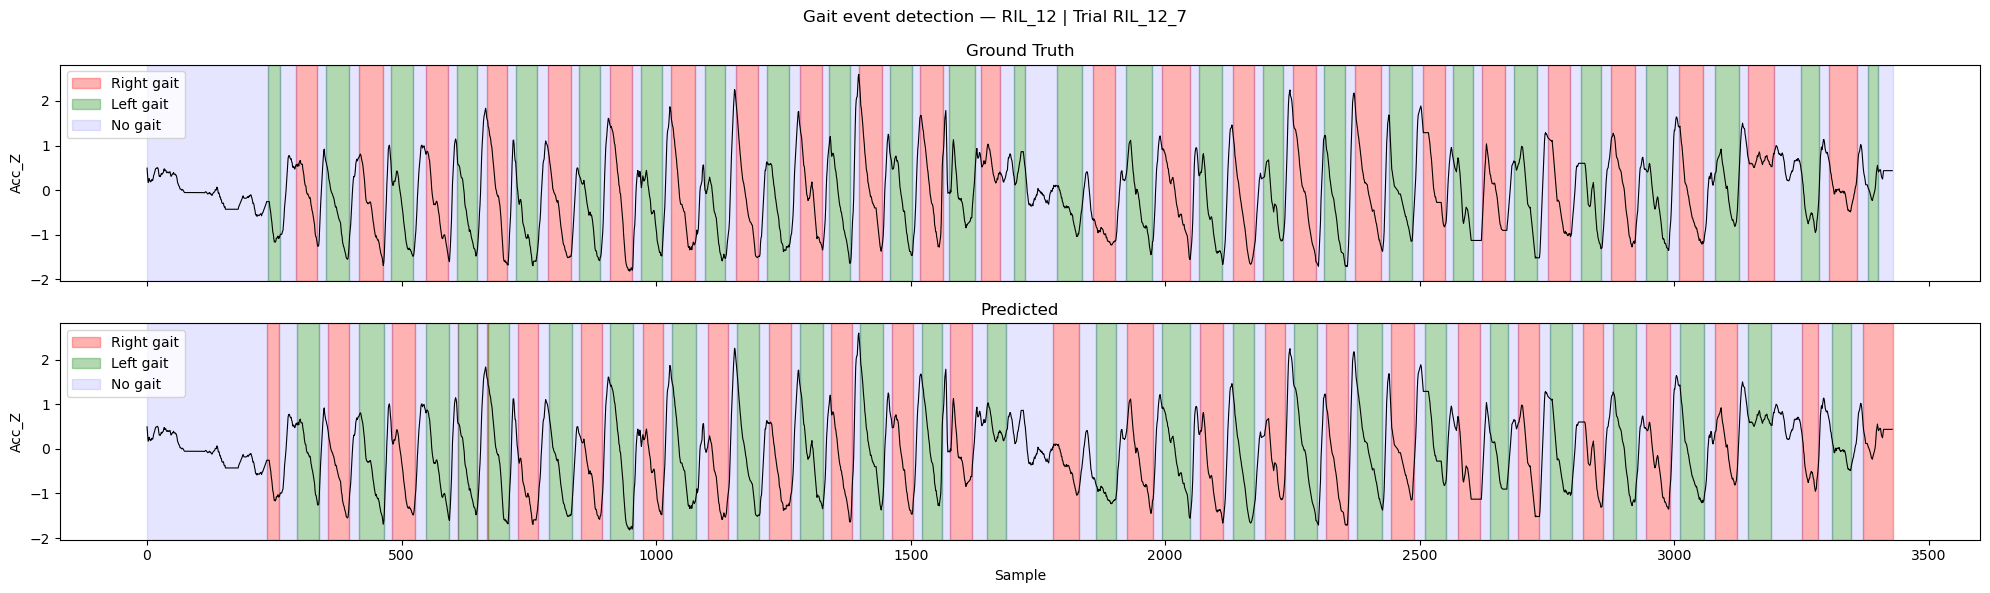

Subject: RIL_12, Trial: RIL_12_8
F1: 0.3916


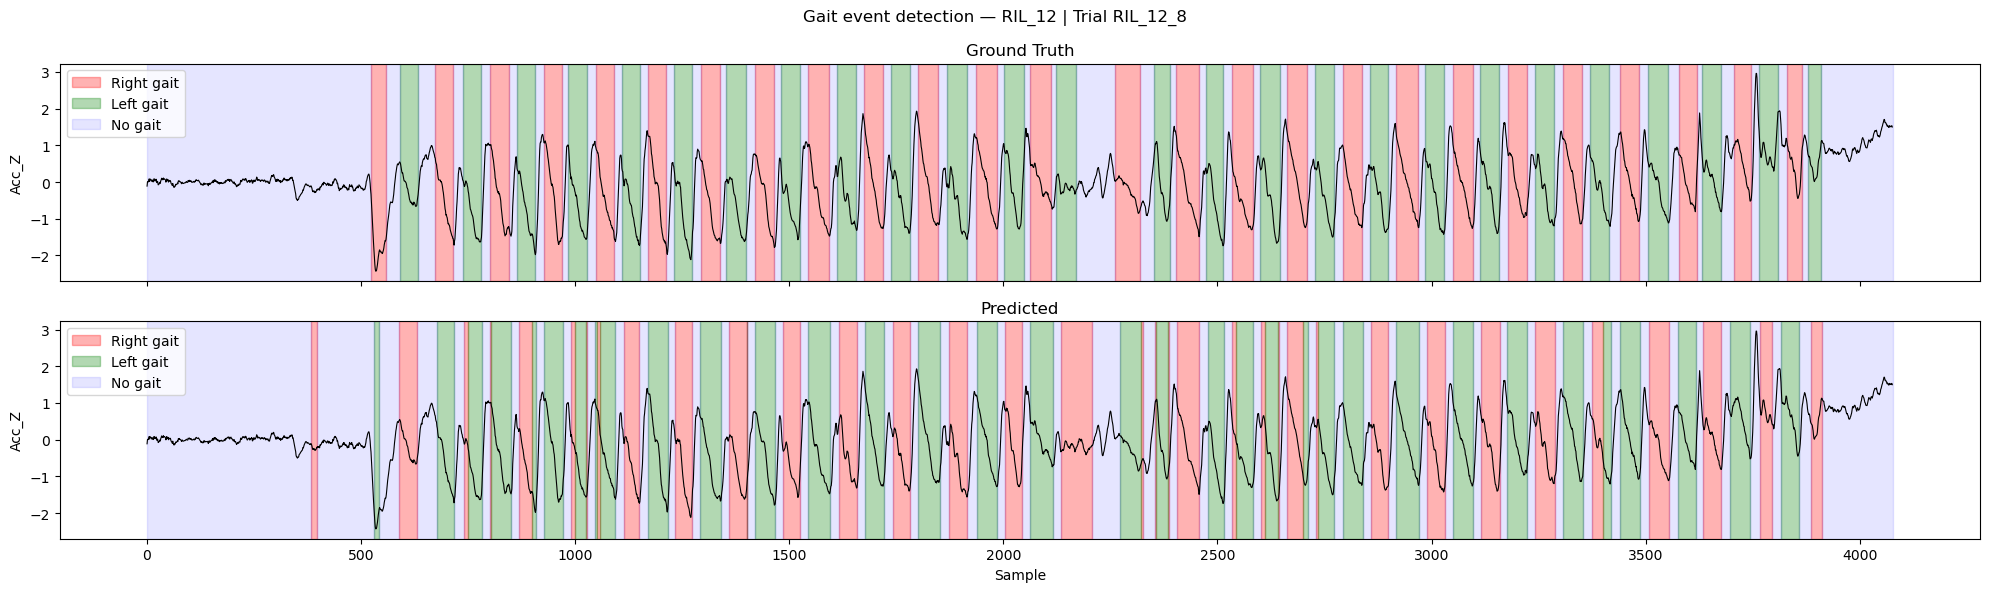

Subject: RIL_12, Trial: RIL_12_9
F1: 0.2779


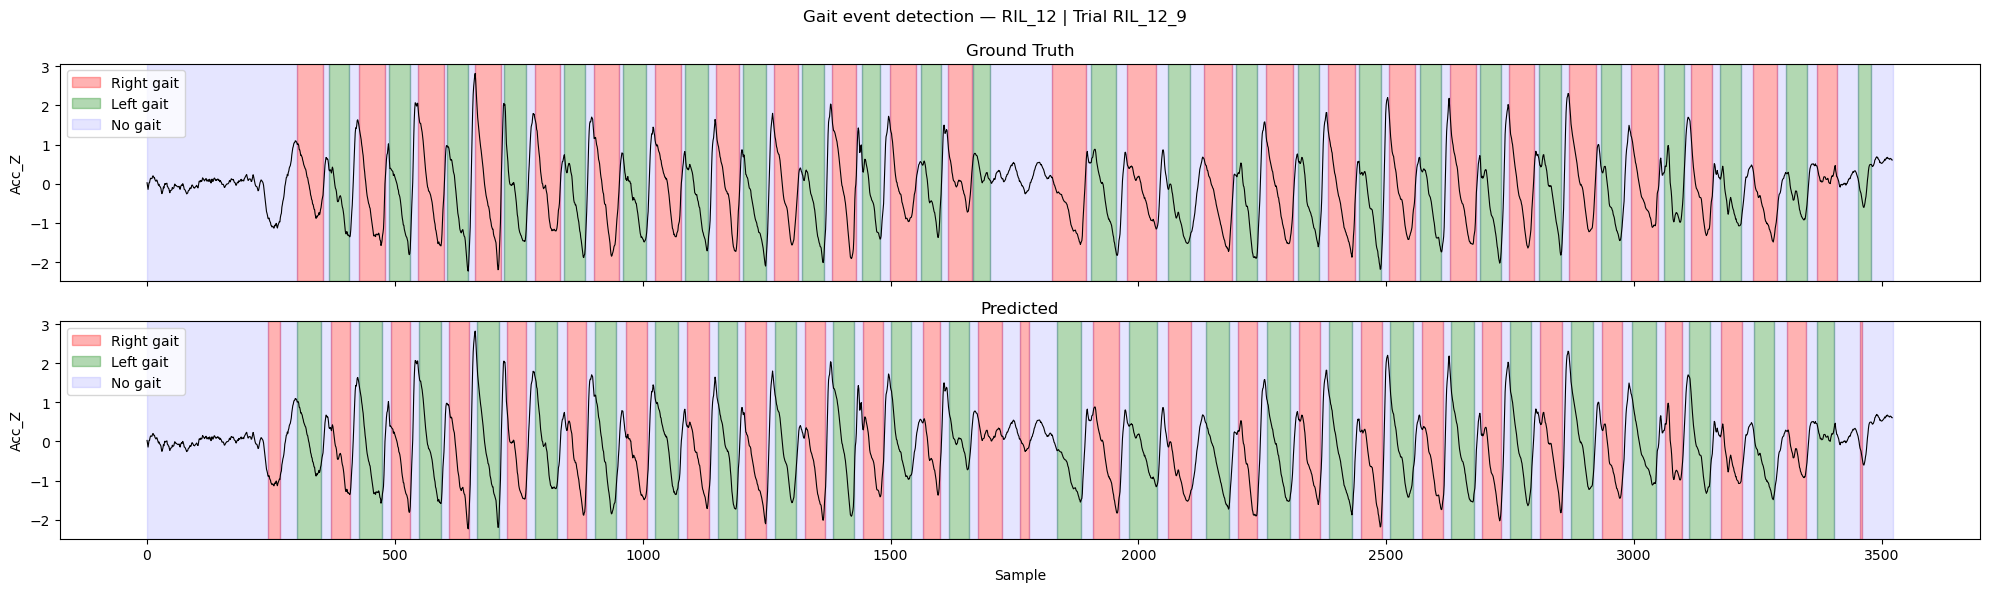

In [29]:
print("Worst subjects (F1 < 0.5):")

ckpt_path = "../checkpoints/loco"

for cohort, subject in worst_subjs:
    if cohort == "HOA":
        c_type = "ortho"
    else:
        c_type = "neuro"

    subj_path, trials = load_patient(base_path, subject)
    for trial in trials:
        print(f"Subject: {subject}, Trial: {trial}")

        y_pred, y_true, signal = predict_trial(
            base_path   = base_path,
            trial_name  = trial,   
            subject     = subject,
            model_name  = "cnnbilstm",
            process     = "free_raw",
            sensors     = ["LB"], 
            window_size = 200,
            stride      = 50,
            out_dir     = f'{ckpt_path}_{cohort}_42'
        )

        print(f"F1: {f1_score(y_true, y_pred, average='macro'):.4f}")


        plot_gait_detection(
            y_true, 
            y_pred,
            trial,
            base_path + f"/{c_type}/{cohort}/{subject}/{trial}",
            title_base=f'Gait event detection — {subject} | Trial {trial}',
            sensor='LB',
            signal_channel='Acc_Z',
            process='free_raw',
            signal=signal
        )
    